# Model Evaluation and Analysis

Analyzes all trained models, visualizes behavior, and generates comprehensive analysis graphs.


In [1]:
import os
import sys
from pathlib import Path
from typing import Dict, List, Tuple, Optional
from collections import defaultdict, Counter
import json

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from tqdm import tqdm
import pandas as pd

import torch
import torch.nn as nn
from torch.distributions import Categorical

import gymnasium as gym
from overcooked_marl_env import OvercookedMARL

# Import classes from training script
from ppo_overcooked import ActorCritic, PettingZooToGymWrapper

# Configuration
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 10
sns.set_style("whitegrid")

# Device detection
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Output directory
OUTPUT_DIR = Path("analysis_output")
OUTPUT_DIR.mkdir(exist_ok=True)


/home/thais/NewOvercookedEnv/venv/lib/python3.12/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


## Helper Functions


In [2]:
def discover_models(models_dir: str = "models") -> List[Path]:
    """Discover all model checkpoint files."""
    models_path = Path(models_dir)
    if not models_path.exists():
        return []
    return list(models_path.glob("*.pth"))


def load_model_checkpoint(model_path: Path) -> Dict:
    """Load model checkpoint and extract information."""
    try:
        checkpoint = torch.load(model_path, map_location='cpu', weights_only=False)
        return {
            'path': str(model_path),
            'filename': model_path.name,
            'state_dict': checkpoint.get('model_state_dict'),
            'config': checkpoint.get('config', {}),
            'training_reward': checkpoint.get('reward', 0.0),
            'episode_rewards': checkpoint.get('episode_rewards', []),
            'episode_lengths': checkpoint.get('episode_lengths', []),
        }
    except Exception as e:
        print(f"Error loading {model_path}: {e}")
        return None


def convert_to_serializable(obj):
    """Convert numpy types and other non-serializable types to Python native types."""
    if isinstance(obj, (np.integer, np.floating)):
        return float(obj)
    elif isinstance(obj, np.ndarray):
        return obj.tolist()
    elif isinstance(obj, dict):
        return {key: convert_to_serializable(value) for key, value in obj.items()}
    elif isinstance(obj, (list, tuple)):
        return [convert_to_serializable(item) for item in obj]
    elif isinstance(obj, (bool, int, float, str)) or obj is None:
        return obj
    else:
        return str(obj)


## Model Evaluation


In [3]:
def evaluate_model(model_path: Path, num_episodes: int = 15, max_steps: int = 800) -> Dict:
    """Evaluate a model and collect comprehensive metrics."""
    checkpoint_data = load_model_checkpoint(model_path)
    if checkpoint_data is None:
        return None
    
    # Create environment
    base_env = OvercookedMARL(
        render_mode=None,
        map_path="overcooked_marl_env/map/maps/simple_map.txt",
        num_fixed_agents=1,
        verbose=False
    )
    env = PettingZooToGymWrapper(base_env)
    
    # Load model
    agent = ActorCritic(env.observation_space, env.action_space).to(device)
    if checkpoint_data['state_dict']:
        agent.load_state_dict(checkpoint_data['state_dict'])
    agent.eval()
    
    # Metrics tracking
    episode_rewards = []
    episode_lengths = []
    deliveries_per_episode = []
    success_episodes = 0
    action_counts = Counter()
    action_sequences = []
    interaction_timings = []
    reward_timings = []
    cumulative_rewards_per_step = []
    
    for episode in range(num_episodes):
        obs, info = env.reset()
        obs = torch.Tensor(obs).to(device)
        
        episode_reward = 0
        episode_length = 0
        episode_actions = []
        episode_interactions = []
        episode_rewards_list = []
        cumulative_reward = 0
        
        initial_delivered = len(info.get('delivered_recipes', []))
        
        for step in range(max_steps):
            with torch.no_grad():
                action, _, _, _ = agent.get_action_and_value(obs.unsqueeze(0))
            action = int(action.item())
            
            next_obs, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated
            
            # Track metrics
            episode_reward += reward
            episode_length += 1
            episode_actions.append(action)
            action_counts[action] += 1
            episode_rewards_list.append(reward)
            cumulative_reward += reward
            cumulative_rewards_per_step.append(cumulative_reward)
            
            if action == 4:  # Interact
                episode_interactions.append(step)
                interaction_timings.append(step)
            
            if reward != 0:
                reward_timings.append((step, reward))
            
            obs = torch.Tensor(next_obs).to(device)
            
            if done:
                break
        
        # Episode completion metrics
        final_delivered = len(info.get('delivered_recipes', []))
        deliveries = final_delivered - initial_delivered
        deliveries_per_episode.append(deliveries)
        
        if deliveries > 0:
            success_episodes += 1
        
        episode_rewards.append(episode_reward)
        episode_lengths.append(episode_length)
        
        # Store action sequence (last 10 actions)
        if len(episode_actions) >= 10:
            action_sequences.append(tuple(episode_actions[-10:]))
    
    env.close()
    
    # Calculate action entropy (exploration metric)
    total_actions = sum(action_counts.values())
    action_probs = [count / total_actions for count in action_counts.values()] if total_actions > 0 else []
    action_entropy = -sum(p * np.log(p + 1e-10) for p in action_probs) if action_probs else 0
    
    # Calculate interaction frequency
    interaction_frequency = action_counts[4] / total_actions if total_actions > 0 else 0
    
    return {
        'model_path': str(model_path),
        'filename': model_path.name,
        'config': checkpoint_data['config'],
        'training_reward': checkpoint_data['training_reward'],
        'eval_rewards': episode_rewards,
        'eval_lengths': episode_lengths,
        'mean_reward': np.mean(episode_rewards),
        'std_reward': np.std(episode_rewards),
        'mean_length': np.mean(episode_lengths),
        'deliveries_per_episode': deliveries_per_episode,
        'mean_deliveries': np.mean(deliveries_per_episode),
        'success_rate': success_episodes / num_episodes,
        'action_distribution': dict(action_counts),
        'action_entropy': action_entropy,
        'interaction_frequency': interaction_frequency,
        'interaction_timings': interaction_timings,
        'reward_timings': reward_timings,
        'cumulative_rewards_per_step': cumulative_rewards_per_step,
        'action_sequences': action_sequences,
    }


## Model Visualization


In [ ]:
def visualize_model_behavior(model_path: Path, num_episodes: int = 3, max_steps: int = 800, 
                             save_frames: bool = True):
    """Visualize model behavior using rgb_array rendering."""
    checkpoint_data = load_model_checkpoint(model_path)
    if checkpoint_data is None:
        return None
    
    # Create environment with rendering
    base_env = OvercookedMARL(
        render_mode="rgb_array",
        map_path="overcooked_marl_env/map/maps/simple_map.txt",
        num_fixed_agents=1,
        verbose=False
    )
    env = PettingZooToGymWrapper(base_env)
    
    # Load model
    agent = ActorCritic(env.observation_space, env.action_space).to(device)
    if checkpoint_data['state_dict']:
        agent.load_state_dict(checkpoint_data['state_dict'])
    agent.eval()
    
    all_frames = []
    all_metrics = []
    
    model_name = model_path.stem
    
    try:
        for episode in range(num_episodes):
            obs, info = env.reset()
            obs = torch.Tensor(obs).to(device)
            
            episode_frames = []
            episode_reward = 0
            episode_steps = 0
            episode_deliveries = len(info.get('delivered_recipes', []))
            
            if base_env.renderer and not base_env.renderer.check_events():
                break
            
            frame = env.render()
            if frame is not None:
                episode_frames.append(frame)
            
            for step in range(max_steps):
                if base_env.renderer and not base_env.renderer.check_events():
                    break
                
                with torch.no_grad():
                    action, _, _, _ = agent.get_action_and_value(obs.unsqueeze(0))
                action = int(action.item())
                
                next_obs, reward, terminated, truncated, info = env.step(action)
                done = terminated or truncated
                
                episode_reward += reward
                episode_steps += 1
                
                if step % 50 == 0 or reward > 0 or action == 4:
                    if base_env.renderer and not base_env.renderer.check_events():
                        break
                    frame = env.render()
                    if frame is not None:
                        episode_frames.append({
                            'frame': frame,
                            'step': step,
                            'reward': episode_reward,
                            'action': action,
                            'deliveries': len(info.get('delivered_recipes', [])) - episode_deliveries
                        })
                
                obs = torch.Tensor(next_obs).to(device)
                
                if done:
                    break
            
            all_frames.append(episode_frames)
            all_metrics.append({
                'episode': episode,
                'reward': episode_reward,
                'steps': episode_steps,
                'deliveries': len(info.get('delivered_recipes', [])) - episode_deliveries
            })
            
            if base_env.renderer and base_env.renderer.should_close:
                break
    except KeyboardInterrupt:
        pass
    finally:
        env.close()
    
    # Create visualization grid
    if save_frames and all_frames:
        max_frames = max(len(frames) for frames in all_frames)
        num_cols = min(5, max_frames)
        fig, axes = plt.subplots(num_episodes, num_cols, figsize=(20, 4 * num_episodes))
        
        # Ensure axes is always a 2D array
        if num_episodes == 1:
            if num_cols == 1:
                # Single subplot: wrap in 2D array
                axes = np.array([[axes]], dtype=object)
            else:
                # Multiple columns: reshape to 2D
                if not isinstance(axes, np.ndarray):
                    axes = np.array([axes])
                axes = axes.reshape(1, -1)
        else:
            if num_cols == 1:
                # Multiple rows, single column: reshape to 2D
                if not isinstance(axes, np.ndarray):
                    axes = np.array(axes)
                axes = axes.reshape(-1, 1)
            else:
                # Multiple rows and columns: already 2D
                if not isinstance(axes, np.ndarray):
                    axes = np.array(axes)
        
        for ep_idx, (ep_frames, ep_metrics) in enumerate(zip(all_frames, all_metrics)):
            for frame_idx, frame_data in enumerate(ep_frames[:num_cols]):
                if frame_idx < axes.shape[1]:
                    ax = axes[ep_idx, frame_idx]
                    frame = frame_data['frame'] if isinstance(frame_data, dict) else frame_data
                    ax.imshow(frame)
                    ax.axis('off')
        
        # Hide unused subplots
        for ep_idx in range(num_episodes):
            for frame_idx in range(num_cols):
                if ep_idx < len(all_frames):
                    if frame_idx >= len(all_frames[ep_idx]):
                        axes[ep_idx, frame_idx].axis('off')
        
        plt.suptitle(f"Model Behavior Visualization: {model_name}", fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / f"visualization_{model_name}.png", dpi=150, bbox_inches='tight')
        plt.show()
    
    return all_frames, all_metrics


## Analysis and Plotting Functions


In [5]:
def generate_analysis_plots(evaluation_results: List[Dict]):
    """Generate comprehensive analysis plots."""
    if not evaluation_results:
        print("No evaluation results to plot")
        return
    
    df = pd.DataFrame(evaluation_results)
    df = df.sort_values(['mean_deliveries', 'mean_reward'], ascending=[False, False]).reset_index(drop=True)
    
    # 1. Bar Chart - Average Deliveries per Model
    fig, ax = plt.subplots(figsize=(14, max(8, len(df) * 0.4)))
    colors = plt.cm.RdYlGn(np.linspace(0.2, 0.8, len(df)))
    bars = ax.barh(range(len(df)), df['mean_deliveries'], color=colors)
    
    # Highlight top 3
    if len(bars) > 0:
        bars[0].set_color('gold')
        bars[0].set_edgecolor('darkgoldenrod')
        bars[0].set_linewidth(2)
    if len(bars) > 1:
        bars[1].set_color('silver')
        bars[1].set_edgecolor('gray')
        bars[1].set_linewidth(2)
    if len(bars) > 2:
        bars[2].set_color('#CD7F32')
        bars[2].set_edgecolor('brown')
        bars[2].set_linewidth(2)
    
    ax.set_yticks(range(len(df)))
    ax.set_yticklabels([f"{row['filename'][:40]}" for _, row in df.iterrows()], fontsize=8)
    ax.set_xlabel('Average Deliveries', fontsize=12)
    ax.set_title('Model Ranking by Average Deliveries (then Reward)', fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3, axis='x')
    
    for i, (bar, deliveries) in enumerate(zip(bars, df['mean_deliveries'])):
        ax.text(deliveries + max(df['mean_deliveries']) * 0.01, bar.get_y() + bar.get_height()/2, 
               f'{deliveries:.2f}', va='center', fontsize=9, fontweight='bold')
    
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "1_ranking_deliveries.png", dpi=150, bbox_inches='tight')
    plt.show()
    
    # 2. Learning Curves - Training Progress
    fig, ax = plt.subplots(figsize=(14, 8))
    top_n = min(10, len(df))
    colors = plt.cm.tab10(np.linspace(0, 1, top_n))
    
    for i in range(top_n):
        row = df.iloc[i]
        # Use training episode_rewards from checkpoint if available
        checkpoint_data = load_model_checkpoint(Path(row['model_path']))
        if checkpoint_data and checkpoint_data.get('episode_rewards'):
            episode_rewards = checkpoint_data['episode_rewards']
            if len(episode_rewards) > 0:
                window = max(1, min(10, len(episode_rewards) // 5))
                smoothed = np.convolve(episode_rewards, np.ones(window)/window, mode='valid')
                x = np.arange(len(smoothed))
                ax.plot(x, smoothed, color=colors[i], linewidth=2, 
                       label=f"Rank {i+1} ({row['mean_reward']:.1f})", alpha=0.8)
    
    ax.set_xlabel('Episode (smoothed)', fontsize=12)
    ax.set_ylabel('Reward', fontsize=12)
    ax.set_title('Learning Curves - Top Models', fontsize=14, fontweight='bold')
    ax.legend(loc='best', fontsize=9)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "2_learning_curves.png", dpi=150, bbox_inches='tight')
    plt.show()
    
    # 3. Box Plot - Reward Distribution
    fig, ax = plt.subplots(figsize=(10, 6))
    bp = ax.boxplot([df['mean_reward']], vert=True, patch_artist=True, widths=0.6,
                    boxprops=dict(facecolor='lightblue', alpha=0.7),
                    medianprops=dict(color='red', linewidth=2))
    ax.scatter([1] * len(df), df['mean_reward'], alpha=0.5, s=80, color='navy', 
              edgecolor='black', linewidth=0.5)
    ax.set_ylabel('Average Reward', fontsize=12)
    ax.set_title('Reward Distribution Across Models', fontsize=14, fontweight='bold')
    ax.set_xticks([1])
    ax.set_xticklabels(['All Models'])
    ax.grid(True, alpha=0.3, axis='y')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "3_reward_distribution.png", dpi=150, bbox_inches='tight')
    plt.show()
    
    # 4. Action Distribution
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    axes = axes.flatten()
    top_n = min(6, len(df))
    
    action_names = ['Up', 'Down', 'Left', 'Right', 'Interact']
    
    for i in range(top_n):
        row = df.iloc[i]
        action_dist = row.get('action_distribution', {})
        if action_dist:
            actions = [action_dist.get(j, 0) for j in range(5)]
            total = sum(actions)
            if total > 0:
                percentages = [a / total * 100 for a in actions]
                ax = axes[i]
                bars = ax.bar(action_names, percentages, color=plt.cm.Set3(range(5)))
                ax.set_title(f"Rank {i+1}: {row['filename'][:30]}", fontsize=10, fontweight='bold')
                ax.set_ylabel('Percentage', fontsize=9)
                ax.set_ylim(0, max(percentages) * 1.2)
                for bar, pct in zip(bars, percentages):
                    if pct > 1:
                        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1, 
                               f'{pct:.1f}%', ha='center', va='bottom', fontsize=8)
                ax.grid(True, alpha=0.3, axis='y')
    
    for i in range(top_n, len(axes)):
        axes[i].axis('off')
    
    plt.suptitle('Action Distribution - Top Models', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "4_action_distribution.png", dpi=150, bbox_inches='tight')
    plt.show()
    
    # 5. Interaction Frequency
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    
    interaction_freqs = df['interaction_frequency'].values * 100
    bars = ax1.barh(range(len(df)), interaction_freqs, color='steelblue')
    ax1.set_yticks(range(len(df)))
    ax1.set_yticklabels([f"{row['filename'][:30]}" for _, row in df.iterrows()], fontsize=8)
    ax1.set_xlabel('Interaction Frequency (%)', fontsize=12)
    ax1.set_title('Interaction Frequency per Model', fontsize=14, fontweight='bold')
    ax1.grid(True, alpha=0.3, axis='x')
    
    ax2.scatter(interaction_freqs, df['mean_reward'], s=100, alpha=0.6, c=df['mean_reward'], 
               cmap='RdYlGn', edgecolors='black', linewidth=1)
    ax2.set_xlabel('Interaction Frequency (%)', fontsize=12)
    ax2.set_ylabel('Average Reward', fontsize=12)
    ax2.set_title('Interaction Frequency vs Reward', fontsize=14, fontweight='bold')
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "5_interaction_analysis.png", dpi=150, bbox_inches='tight')
    plt.show()
    
    # 6. Success Rate and Deliveries
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    
    success_rates = df['success_rate'].values * 100
    bars = ax1.barh(range(len(df)), success_rates, color='green', alpha=0.7)
    ax1.set_yticks(range(len(df)))
    ax1.set_yticklabels([f"{row['filename'][:30]}" for _, row in df.iterrows()], fontsize=8)
    ax1.set_xlabel('Success Rate (%)', fontsize=12)
    ax1.set_title('Success Rate (Episodes with Deliveries)', fontsize=14, fontweight='bold')
    ax1.grid(True, alpha=0.3, axis='x')
    ax1.set_xlim(0, 105)
    
    all_deliveries = []
    model_labels = []
    for _, row in df.iterrows():
        deliveries = row.get('deliveries_per_episode', [])
        all_deliveries.extend(deliveries)
        model_labels.extend([row['filename'][:20]] * len(deliveries))
    
    if all_deliveries:
        delivery_df = pd.DataFrame({'deliveries': all_deliveries, 'model': model_labels})
        top_models = df.head(6)['filename'].tolist()
        delivery_df_filtered = delivery_df[delivery_df['model'].isin([m[:20] for m in top_models])]
        
        if len(delivery_df_filtered) > 0:
            delivery_df_filtered.boxplot(column='deliveries', by='model', ax=ax2, rot=45)
            ax2.set_title('Delivery Distribution - Top Models', fontsize=14, fontweight='bold')
            ax2.set_xlabel('Model', fontsize=10)
            ax2.set_ylabel('Deliveries per Episode', fontsize=12)
            ax2.get_figure().suptitle('')
    
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "6_success_deliveries.png", dpi=150, bbox_inches='tight')
    plt.show()
    
    # 7. Hyperparameter Analysis
    if 'config' in df.columns and df['config'].notna().any():
        try:
            hyperparams = []
            for _, row in df.iterrows():
                config = row.get('config', {})
                hyperparams.append({
                    'update_epochs': config.get('update_epochs', 0),
                    'ent_coef': config.get('ent_coef', 0),
                    'gae_lambda': config.get('gae_lambda', 0),
                    'reward': row['mean_reward']
                })
            
            hp_df = pd.DataFrame(hyperparams)
            
            fig, axes = plt.subplots(2, 2, figsize=(16, 12))
            
            axes[0, 0].scatter(hp_df['update_epochs'], hp_df['reward'], 
                             s=100, alpha=0.6, c=hp_df['reward'], cmap='RdYlGn', 
                             edgecolors='black', linewidth=1)
            axes[0, 0].set_xlabel('Update Epochs', fontsize=12)
            axes[0, 0].set_ylabel('Average Reward', fontsize=12)
            axes[0, 0].set_title('Update Epochs vs Reward', fontsize=12, fontweight='bold')
            axes[0, 0].grid(True, alpha=0.3)
            
            axes[0, 1].scatter(hp_df['ent_coef'], hp_df['reward'], 
                             s=100, alpha=0.6, c=hp_df['reward'], cmap='RdYlGn', 
                             edgecolors='black', linewidth=1)
            axes[0, 1].set_xlabel('Entropy Coefficient', fontsize=12)
            axes[0, 1].set_ylabel('Average Reward', fontsize=12)
            axes[0, 1].set_title('Entropy Coefficient vs Reward', fontsize=12, fontweight='bold')
            axes[0, 1].grid(True, alpha=0.3)
            
            axes[1, 0].scatter(hp_df['gae_lambda'], hp_df['reward'], 
                             s=100, alpha=0.6, c=hp_df['reward'], cmap='RdYlGn', 
                             edgecolors='black', linewidth=1)
            axes[1, 0].set_xlabel('GAE Lambda', fontsize=12)
            axes[1, 0].set_ylabel('Average Reward', fontsize=12)
            axes[1, 0].set_title('GAE Lambda vs Reward', fontsize=12, fontweight='bold')
            axes[1, 0].grid(True, alpha=0.3)
            
            corr_data = hp_df[['update_epochs', 'ent_coef', 'gae_lambda', 'reward']].corr()
            sns.heatmap(corr_data, annot=True, fmt='.2f', cmap='coolwarm', center=0, 
                    square=True, linewidths=1, ax=axes[1, 1], cbar_kws={"shrink": 0.8})
            axes[1, 1].set_title('Hyperparameter Correlation', fontsize=12, fontweight='bold')
            
            plt.suptitle('Hyperparameter Analysis', fontsize=14, fontweight='bold')
            plt.tight_layout()
            plt.savefig(OUTPUT_DIR / "7_hyperparameter_analysis.png", dpi=150, bbox_inches='tight')
            plt.show()
        except Exception as e:
            print(f"Error in hyperparameter analysis: {e}")
    
    # 8. Training vs Evaluation Comparison
    if 'training_reward' in df.columns:
        fig, ax = plt.subplots(figsize=(10, 8))
        ax.scatter(df['training_reward'], df['mean_reward'], s=100, alpha=0.6, 
                  c=df['mean_reward'], cmap='RdYlGn', edgecolors='black', linewidth=1)
        
        min_val = min(df['training_reward'].min(), df['mean_reward'].min())
        max_val = max(df['training_reward'].max(), df['mean_reward'].max())
        ax.plot([min_val, max_val], [min_val, max_val], 'k--', alpha=0.5, linewidth=2, 
               label='Perfect Match')
        
        ax.set_xlabel('Training Reward', fontsize=12)
        ax.set_ylabel('Evaluation Reward', fontsize=12)
        ax.set_title('Training vs Evaluation Reward', fontsize=14, fontweight='bold')
        ax.legend()
        ax.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / "8_training_vs_eval.png", dpi=150, bbox_inches='tight')
        plt.show()
    
    # 9. Radar Chart - Top Models Comparison
    if len(df) > 0:
        try:
            top_n = min(5, len(df))
            categories = ['Reward', 'Success Rate', 'Interaction', 'Deliveries', 'Exploration']
            
            fig, ax = plt.subplots(figsize=(12, 10), subplot_kw=dict(projection='polar'))
            
            angles = np.linspace(0, 2 * np.pi, len(categories), endpoint=False).tolist()
            angles += angles[:1]
            
            for i in range(top_n):
                row = df.iloc[i]
                values = [
                    row['mean_reward'] / df['mean_reward'].max() * 100,
                    row['success_rate'] * 100,
                    row['interaction_frequency'] * 100,
                    row['mean_deliveries'] / max(df['mean_deliveries'].max(), 1) * 100,
                    row['action_entropy'] / max(df['action_entropy'].max(), 1) * 100
                ]
                values += values[:1]
                
                ax.plot(angles, values, 'o-', linewidth=2, label=f"Rank {i+1}", alpha=0.7)
                ax.fill(angles, values, alpha=0.15)
            
            ax.set_xticks(angles[:-1])
            ax.set_xticklabels(categories)
            ax.set_ylim(0, 100)
            ax.set_title('Model Comparison Radar Chart', fontsize=14, fontweight='bold', pad=20)
            ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
            ax.grid(True)
            
            plt.tight_layout()
            plt.savefig(OUTPUT_DIR / "9_radar_chart.png", dpi=150, bbox_inches='tight')
            plt.show()
        except Exception as e:
            print(f"Error creating radar chart: {e}")
    
    # 10. Dual Ranking Comparison - Success Rate vs Reward
    if len(df) > 0:
        try:
            df_success = df.sort_values('success_rate', ascending=False).reset_index(drop=True)
            df_reward = df.sort_values('mean_reward', ascending=False).reset_index(drop=True)
            
            top_n = min(5, len(df))
            top_success = df_success.head(top_n)
            top_reward = df_reward.head(top_n)
            
            # Find models that appear in both rankings
            success_names = set(top_success['filename'].str[:30])
            reward_names = set(top_reward['filename'].str[:30])
            overlap_names = success_names.intersection(reward_names)
            
            fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, max(8, top_n * 0.6)))
            
            # Left: Top by Success Rate
            colors1 = ['#2ecc71' if name[:30] in overlap_names else '#27ae60' for name in top_success['filename']]
            bars1 = ax1.barh(range(len(top_success)), top_success['success_rate'] * 100, color=colors1, alpha=0.8)
            ax1.set_yticks(range(len(top_success)))
            ax1.set_yticklabels([f"{row['filename'][:30]}" for _, row in top_success.iterrows()], fontsize=9)
            ax1.set_xlabel('Success Rate (%)', fontsize=12)
            ax1.set_title('Top 5 Models by Success Rate', fontsize=14, fontweight='bold')
            ax1.grid(True, alpha=0.3, axis='x')
            ax1.set_xlim(0, 105)
            
            for i, (bar, val) in enumerate(zip(bars1, top_success['success_rate'] * 100)):
                ax1.text(val + 1, bar.get_y() + bar.get_height()/2, 
                        f'{val:.1f}%', va='center', fontsize=9, fontweight='bold')
                # Add reward rank annotation
                filename = top_success.iloc[i]['filename']
                reward_rank = df_reward[df_reward['filename'] == filename].index[0] + 1 if len(df_reward[df_reward['filename'] == filename]) > 0 else None
                if reward_rank:
                    ax1.text(-5, bar.get_y() + bar.get_height()/2, 
                            f'R#{reward_rank}', va='center', ha='right', fontsize=8, style='italic')
            
            # Right: Top by Reward
            colors2 = ['#f39c12' if name[:30] in overlap_names else '#e67e22' for name in top_reward['filename']]
            bars2 = ax2.barh(range(len(top_reward)), top_reward['mean_reward'], color=colors2, alpha=0.8)
            ax2.set_yticks(range(len(top_reward)))
            ax2.set_yticklabels([f"{row['filename'][:30]}" for _, row in top_reward.iterrows()], fontsize=9)
            ax2.set_xlabel('Average Reward', fontsize=12)
            ax2.set_title('Top 5 Models by Reward', fontsize=14, fontweight='bold')
            ax2.grid(True, alpha=0.3, axis='x')
            
            for i, (bar, val) in enumerate(zip(bars2, top_reward['mean_reward'])):
                ax2.text(val + max(top_reward['mean_reward']) * 0.01, bar.get_y() + bar.get_height()/2, 
                        f'{val:.1f}', va='center', fontsize=9, fontweight='bold')
                # Add success rank annotation
                filename = top_reward.iloc[i]['filename']
                success_rank = df_success[df_success['filename'] == filename].index[0] + 1 if len(df_success[df_success['filename'] == filename]) > 0 else None
                if success_rank:
                    ax2.text(-max(top_reward['mean_reward']) * 0.05, bar.get_y() + bar.get_height()/2, 
                            f'S#{success_rank}', va='center', ha='right', fontsize=8, style='italic')
            
            plt.suptitle('Dual Ranking Comparison: Success Rate vs Reward', fontsize=16, fontweight='bold')
            plt.tight_layout()
            plt.savefig(OUTPUT_DIR / "10_dual_ranking_comparison.png", dpi=150, bbox_inches='tight')
            plt.show()
        except Exception as e:
            print(f"Error creating dual ranking comparison: {e}")
    
    # 11. Scatter Plot - Success Rate vs Reward
    if len(df) > 0:
        try:
            best_success_idx = df['success_rate'].idxmax()
            best_reward_idx = df['mean_reward'].idxmax()
            
            fig, ax = plt.subplots(figsize=(12, 8))
            
            # Plot all models
            scatter = ax.scatter(df['success_rate'] * 100, df['mean_reward'], 
                              s=df['mean_deliveries'] * 100 + 50, alpha=0.6, 
                              c=df['mean_reward'], cmap='RdYlGn', 
                              edgecolors='black', linewidth=1)
            
            # Highlight best by success rate
            best_success = df.iloc[best_success_idx]
            ax.scatter(best_success['success_rate'] * 100, best_success['mean_reward'], 
                      s=400, marker='*', color='#2ecc71', edgecolors='darkgreen', 
                      linewidth=3, label=f"Best Success Rate: {best_success['filename'][:25]}", zorder=5)
            
            # Highlight best by reward
            best_reward = df.iloc[best_reward_idx]
            ax.scatter(best_reward['success_rate'] * 100, best_reward['mean_reward'], 
                      s=400, marker='*', color='#f39c12', edgecolors='darkorange', 
                      linewidth=3, label=f"Best Reward: {best_reward['filename'][:25]}", zorder=5)
            
            # Add correlation line
            if len(df) > 1:
                z = np.polyfit(df['success_rate'] * 100, df['mean_reward'], 1)
                p = np.poly1d(z)
                x_line = np.linspace(df['success_rate'].min() * 100, df['success_rate'].max() * 100, 100)
                ax.plot(x_line, p(x_line), "r--", alpha=0.5, linewidth=2, label='Trend Line')
                
                # Calculate correlation
                corr = np.corrcoef(df['success_rate'] * 100, df['mean_reward'])[0, 1]
                ax.text(0.05, 0.95, f'Correlation: {corr:.3f}', transform=ax.transAxes, 
                       fontsize=11, verticalalignment='top',
                       bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
            
            ax.set_xlabel('Success Rate (%)', fontsize=12)
            ax.set_ylabel('Average Reward', fontsize=12)
            ax.set_title('Success Rate vs Reward (bubble size = deliveries)', fontsize=14, fontweight='bold')
            ax.legend(loc='best', fontsize=9)
            ax.grid(True, alpha=0.3)
            
            plt.colorbar(scatter, ax=ax, label='Reward')
            plt.tight_layout()
            plt.savefig(OUTPUT_DIR / "11_success_vs_reward_scatter.png", dpi=150, bbox_inches='tight')
            plt.show()
        except Exception as e:
            print(f"Error creating scatter plot: {e}")
    
    # 12. Detailed Comparison of Top Models
    if len(df) > 0:
        try:
            df_success = df.sort_values('success_rate', ascending=False).reset_index(drop=True)
            df_reward = df.sort_values('mean_reward', ascending=False).reset_index(drop=True)
            
            top_n = min(3, len(df))
            top_success = df_success.head(top_n)
            top_reward = df_reward.head(top_n)
            
            # Normalize metrics for comparison (0-100 scale)
            metrics = ['success_rate', 'mean_reward', 'mean_deliveries', 'interaction_frequency']
            normalized_data = []
            
            for _, row in top_success.iterrows():
                normalized_data.append({
                    'Model': f"S#{_+1}",
                    'Type': 'Success Rate',
                    'Success Rate': row['success_rate'] * 100,
                    'Reward': (row['mean_reward'] / df['mean_reward'].max()) * 100 if df['mean_reward'].max() > 0 else 0,
                    'Deliveries': (row['mean_deliveries'] / max(df['mean_deliveries'].max(), 1)) * 100,
                    'Interaction': row['interaction_frequency'] * 100
                })
            
            for _, row in top_reward.iterrows():
                normalized_data.append({
                    'Model': f"R#{_+1}",
                    'Type': 'Reward',
                    'Success Rate': row['success_rate'] * 100,
                    'Reward': (row['mean_reward'] / df['mean_reward'].max()) * 100 if df['mean_reward'].max() > 0 else 0,
                    'Deliveries': (row['mean_deliveries'] / max(df['mean_deliveries'].max(), 1)) * 100,
                    'Interaction': row['interaction_frequency'] * 100
                })
            
            comp_df = pd.DataFrame(normalized_data)
            
            x = np.arange(len(comp_df))
            width = 0.2
            
            fig, ax = plt.subplots(figsize=(16, 8))
            
            ax.bar(x - 1.5*width, comp_df['Success Rate'], width, label='Success Rate (%)', color='#2ecc71', alpha=0.8)
            ax.bar(x - 0.5*width, comp_df['Reward'], width, label='Reward (normalized)', color='#f39c12', alpha=0.8)
            ax.bar(x + 0.5*width, comp_df['Deliveries'], width, label='Deliveries (normalized)', color='#3498db', alpha=0.8)
            ax.bar(x + 1.5*width, comp_df['Interaction'], width, label='Interaction Freq (%)', color='#9b59b6', alpha=0.8)
            
            ax.set_xlabel('Model', fontsize=12)
            ax.set_ylabel('Normalized Score (0-100)', fontsize=12)
            ax.set_title('Detailed Comparison: Top 3 by Success Rate vs Top 3 by Reward', fontsize=14, fontweight='bold')
            ax.set_xticks(x)
            ax.set_xticklabels([f"{row['Model']}\n{row['Type']}" for _, row in comp_df.iterrows()], fontsize=9)
            ax.legend(loc='upper left', fontsize=10)
            ax.grid(True, alpha=0.3, axis='y')
            ax.set_ylim(0, 110)
            
            plt.tight_layout()
            plt.savefig(OUTPUT_DIR / "12_top_models_comparison.png", dpi=150, bbox_inches='tight')
            plt.show()
        except Exception as e:
            print(f"Error creating detailed comparison: {e}")
    
    # 13. Trade-off Analysis
    if len(df) > 0:
        try:
            df_sorted = df.sort_values('success_rate', ascending=True).reset_index(drop=True)
            
            fig, ax1 = plt.subplots(figsize=(14, 8))
            
            # Primary axis: Success Rate
            color1 = '#2ecc71'
            ax1.set_xlabel('Model Index (sorted by Success Rate)', fontsize=12)
            ax1.set_ylabel('Success Rate (%)', color=color1, fontsize=12)
            line1 = ax1.plot(range(len(df_sorted)), df_sorted['success_rate'] * 100, 
                           'o-', color=color1, linewidth=2, markersize=8, label='Success Rate')
            ax1.tick_params(axis='y', labelcolor=color1)
            ax1.grid(True, alpha=0.3)
            
            # Secondary axis: Reward
            ax2 = ax1.twinx()
            color2 = '#f39c12'
            ax2.set_ylabel('Average Reward', color=color2, fontsize=12)
            line2 = ax2.plot(range(len(df_sorted)), df_sorted['mean_reward'], 
                           's-', color=color2, linewidth=2, markersize=8, label='Reward', alpha=0.7)
            ax2.tick_params(axis='y', labelcolor=color2)
            
            # Highlight sweet spot (top quartile in both metrics)
            success_q75 = df_sorted['success_rate'].quantile(0.75)
            reward_q75 = df_sorted['mean_reward'].quantile(0.75)
            sweet_spot = df_sorted[(df_sorted['success_rate'] >= success_q75) & 
                                  (df_sorted['mean_reward'] >= reward_q75)]
            
            if len(sweet_spot) > 0:
                for idx in sweet_spot.index:
                    ax1.axvline(x=idx, color='purple', linestyle='--', alpha=0.5, linewidth=1)
                ax1.text(0.02, 0.98, f'Sweet Spot: {len(sweet_spot)} models\n(high in both metrics)', 
                        transform=ax1.transAxes, fontsize=10, verticalalignment='top',
                        bbox=dict(boxstyle='round', facecolor='purple', alpha=0.2))
            
            # Combine legends
            lines = line1 + line2
            labels = [l.get_label() for l in lines]
            ax1.legend(lines, labels, loc='upper left', fontsize=10)
            
            ax1.set_title('Trade-off Analysis: Success Rate vs Reward', fontsize=14, fontweight='bold')
            plt.tight_layout()
            plt.savefig(OUTPUT_DIR / "13_tradeoff_analysis.png", dpi=150, bbox_inches='tight')
            plt.show()
        except Exception as e:
            print(f"Error creating trade-off analysis: {e}")
    
    # 14. Comparative Table
    if len(df) > 0:
        try:
            df_success = df.sort_values('success_rate', ascending=False).reset_index(drop=True)
            df_reward = df.sort_values('mean_reward', ascending=False).reset_index(drop=True)
            
            top_n = min(5, len(df))
            
            fig, ax = plt.subplots(figsize=(20, 12))
            ax.axis('tight')
            ax.axis('off')
            
            # Prepare table data
            table_data = []
            headers = ['Rank', 'Model', 'Success Rate (%)', 'Reward', 'Deliveries', 'Interaction (%)']
            
            # Top by Success Rate
            table_data.append(['', 'TOP BY SUCCESS RATE', '', '', '', ''])
            for i in range(top_n):
                row = df_success.iloc[i]
                table_data.append([
                    f'S#{i+1}',
                    row['filename'][:35],
                    f"{row['success_rate']*100:.1f}",
                    f"{row['mean_reward']:.1f}",
                    f"{row['mean_deliveries']:.2f}",
                    f"{row['interaction_frequency']*100:.1f}"
                ])
            
            table_data.append(['', '', '', '', '', ''])
            
            # Top by Reward
            table_data.append(['', 'TOP BY REWARD', '', '', '', ''])
            for i in range(top_n):
                row = df_reward.iloc[i]
                table_data.append([
                    f'R#{i+1}',
                    row['filename'][:35],
                    f"{row['success_rate']*100:.1f}",
                    f"{row['mean_reward']:.1f}",
                    f"{row['mean_deliveries']:.2f}",
                    f"{row['interaction_frequency']*100:.1f}"
                ])
            
            # Create table
            table = ax.table(cellText=table_data, colLabels=headers, 
                           cellLoc='left', loc='center', 
                           colWidths=[0.08, 0.4, 0.12, 0.12, 0.12, 0.12])
            
            table.auto_set_font_size(False)
            table.set_fontsize(9)
            table.scale(1, 2)
            
            # Style table
            for i in range(len(headers)):
                table[(0, i)].set_facecolor('#34495e')
                table[(0, i)].set_text_props(weight='bold', color='white')
            
            # Highlight section headers
            for i, row in enumerate(table_data):
                if len(row) > 1 and row[1] in ['TOP BY SUCCESS RATE', 'TOP BY REWARD']:
                    for j in range(len(headers)):
                        table[(i+1, j)].set_facecolor('#3498db')
                        table[(i+1, j)].set_text_props(weight='bold', color='white')
            
            # Alternate row colors
            current_section = None
            for i, row in enumerate(table_data):
                if len(row) > 1 and 'TOP BY' in row[1]:
                    current_section = row[1]
                elif len(row) > 1 and row[1] != '':
                    if i % 2 == 0:
                        for j in range(len(headers)):
                            table[(i+1, j)].set_facecolor('#ecf0f1')
            
            ax.set_title('Comparative Table: Top 5 Models by Success Rate vs Reward', 
                        fontsize=16, fontweight='bold', pad=20)
            
            plt.tight_layout()
            plt.savefig(OUTPUT_DIR / "14_comparative_table.png", dpi=150, bbox_inches='tight')
            plt.show()
        except Exception as e:
            print(f"Error creating comparative table: {e}")
    
    print(f"\nAnalysis plots saved to {OUTPUT_DIR}/")


## Main Execution


Found 12 models


Evaluating: 100%|██████████| 12/12 [01:07<00:00,  5.63s/it]


Evaluation results saved to: analysis_output/evaluation_results.json


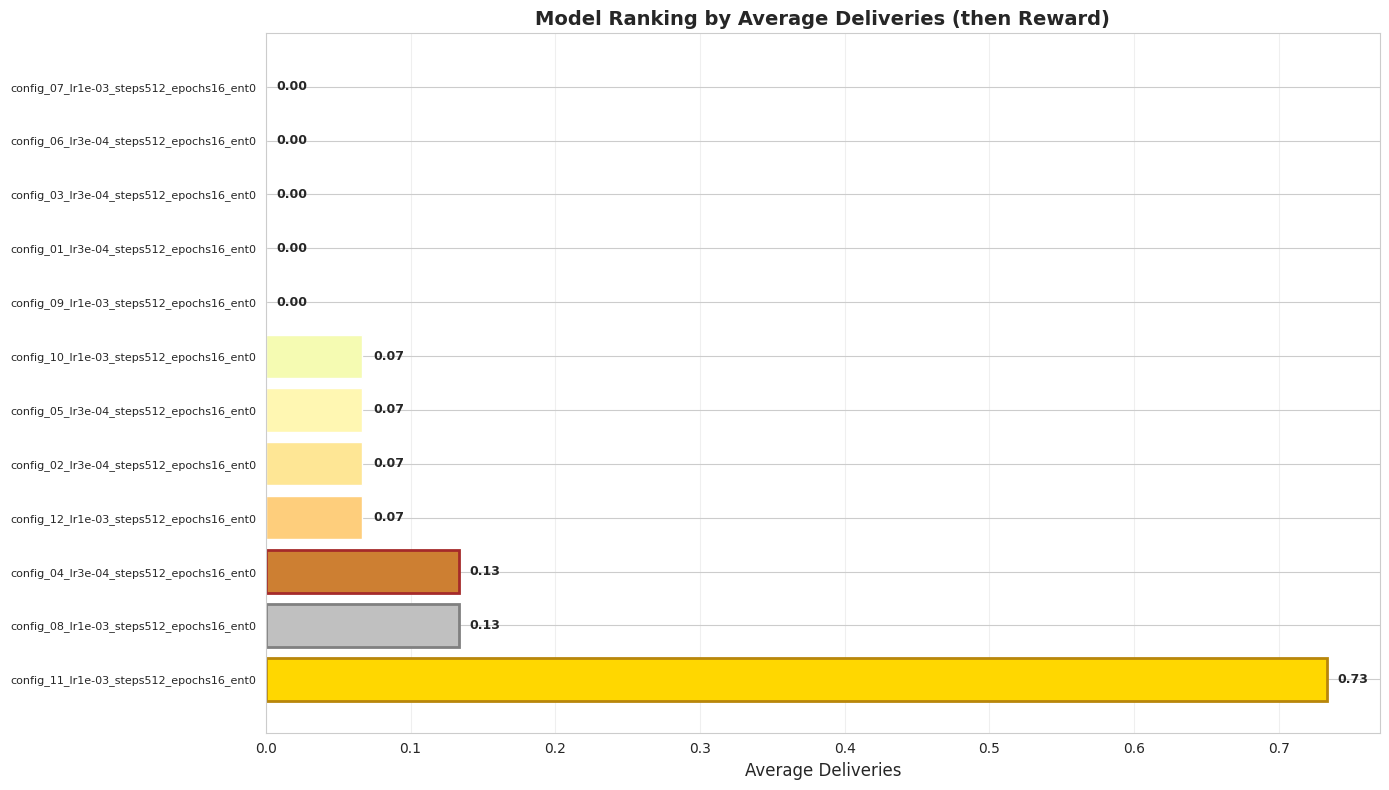

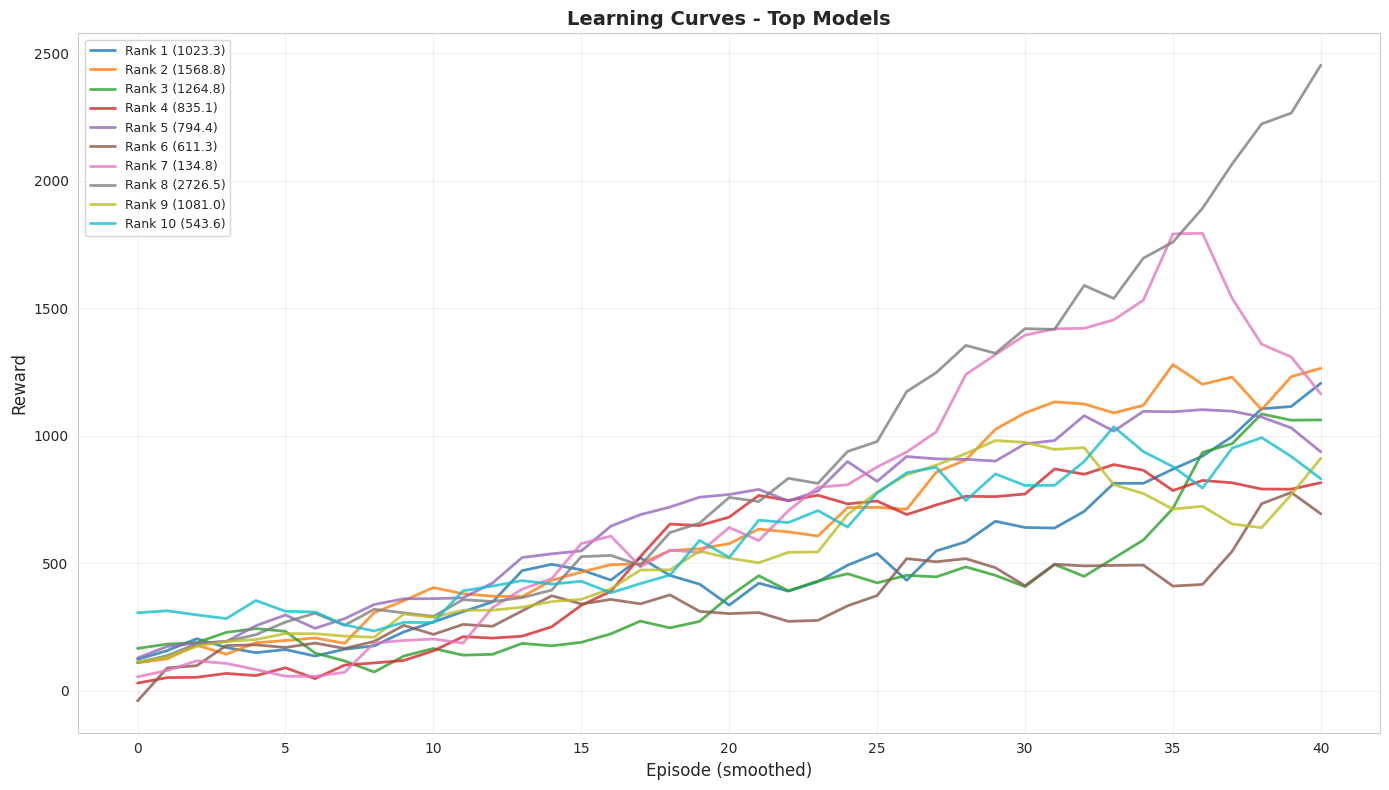

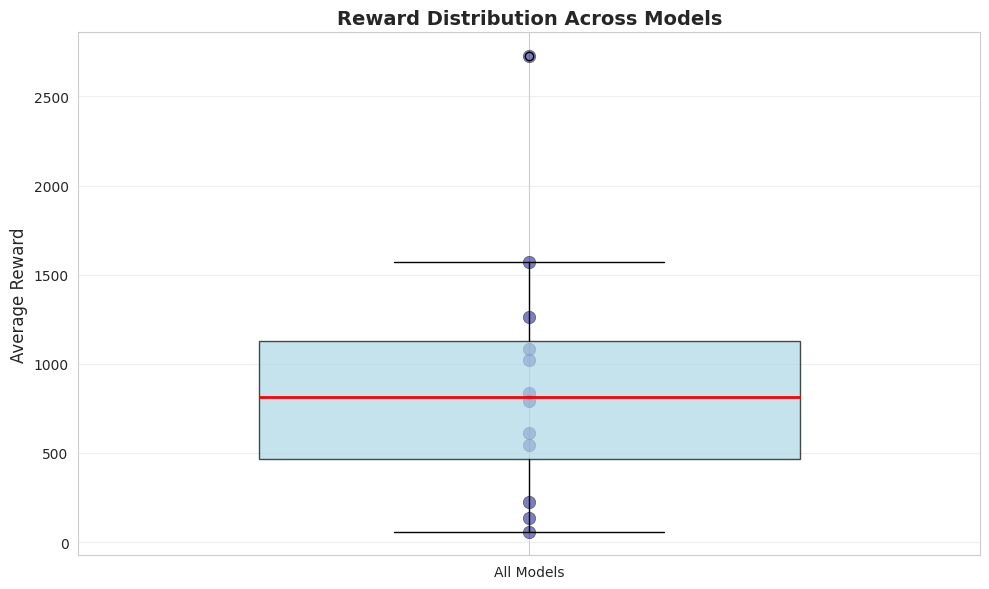

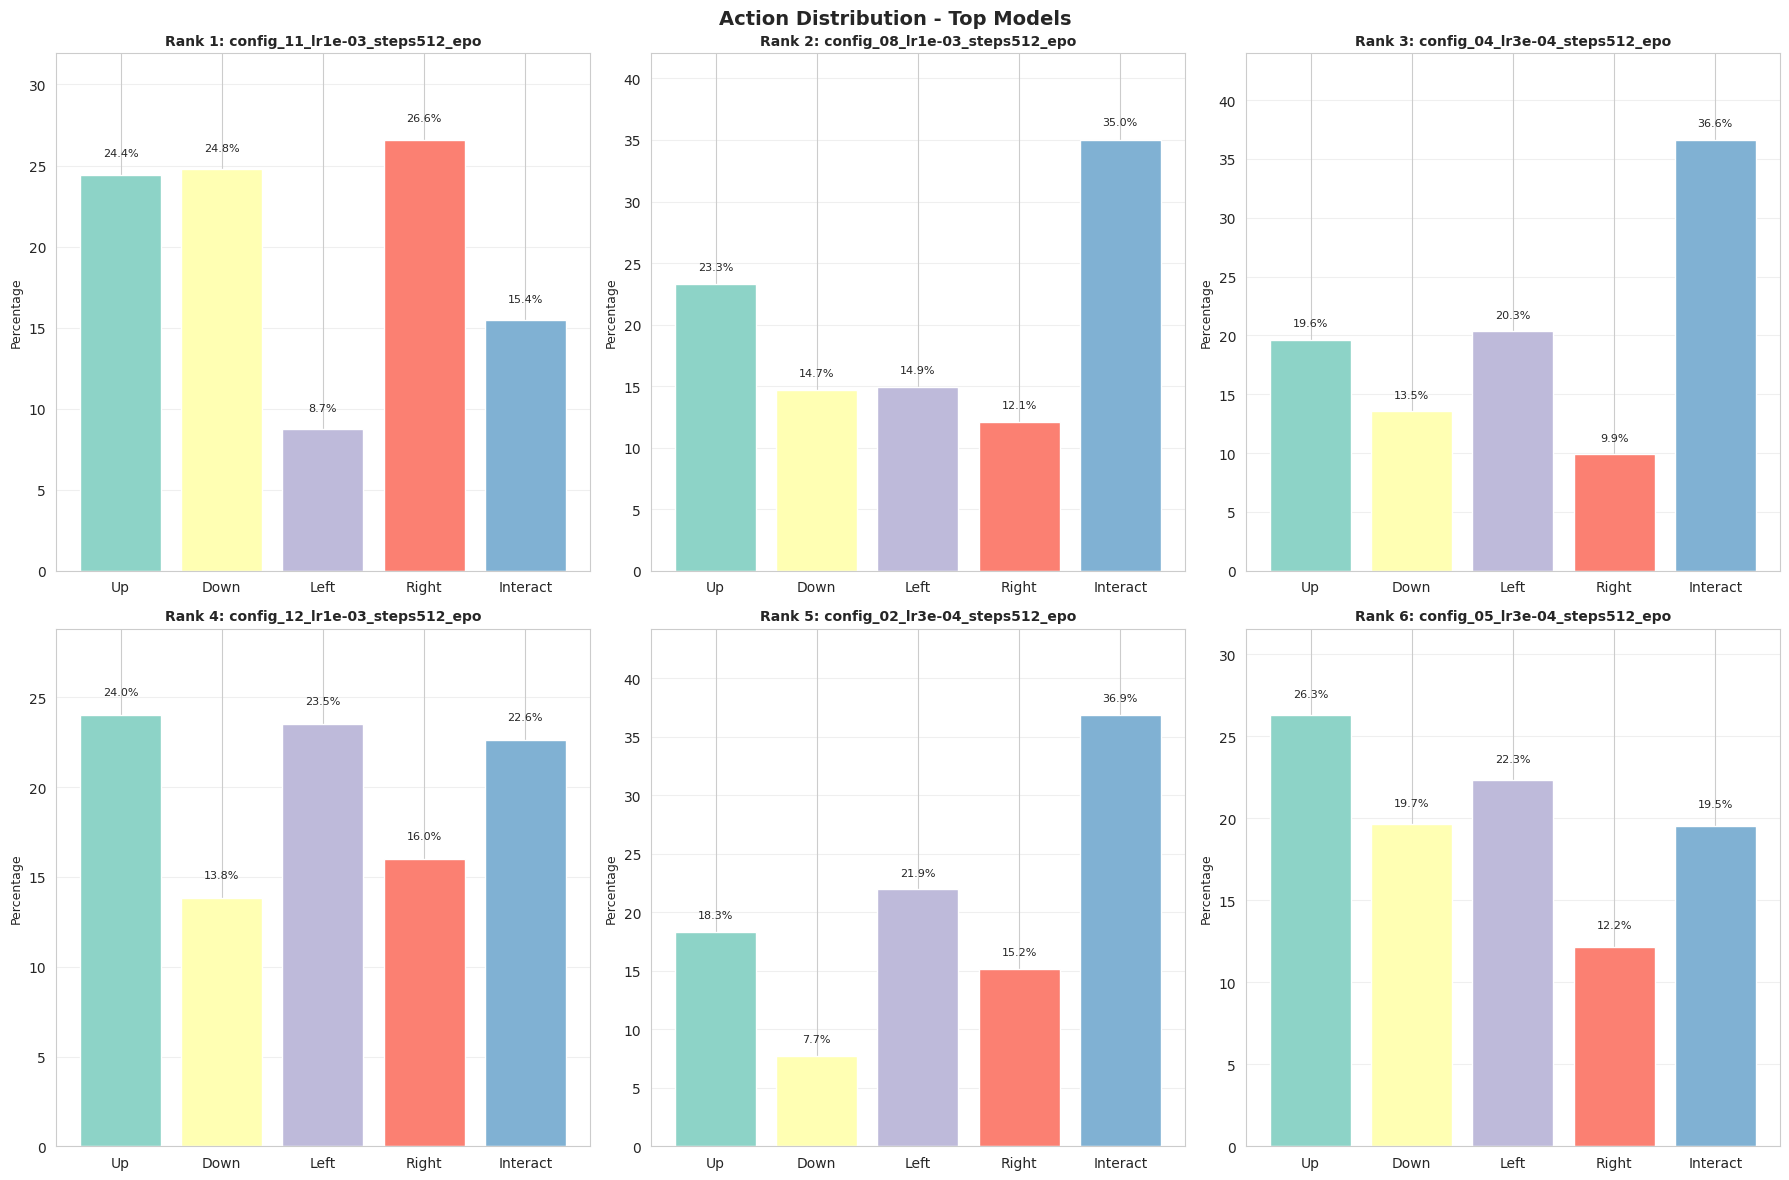

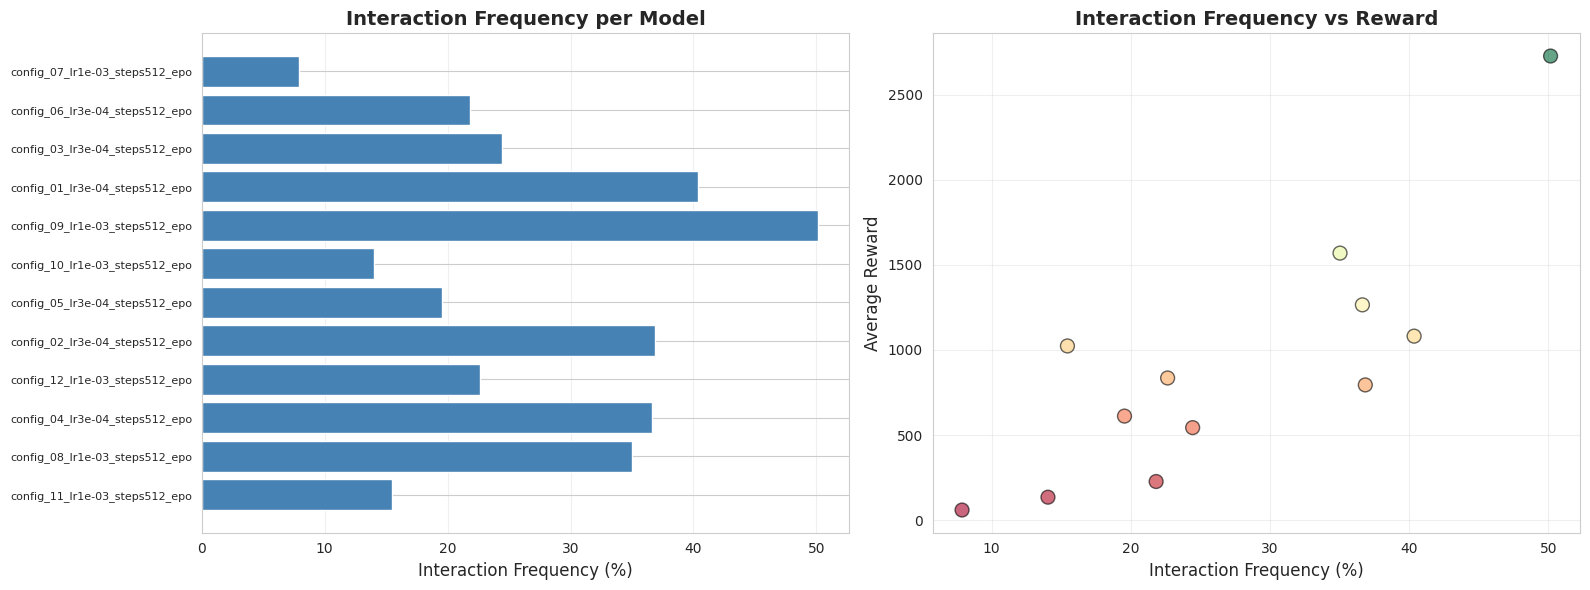

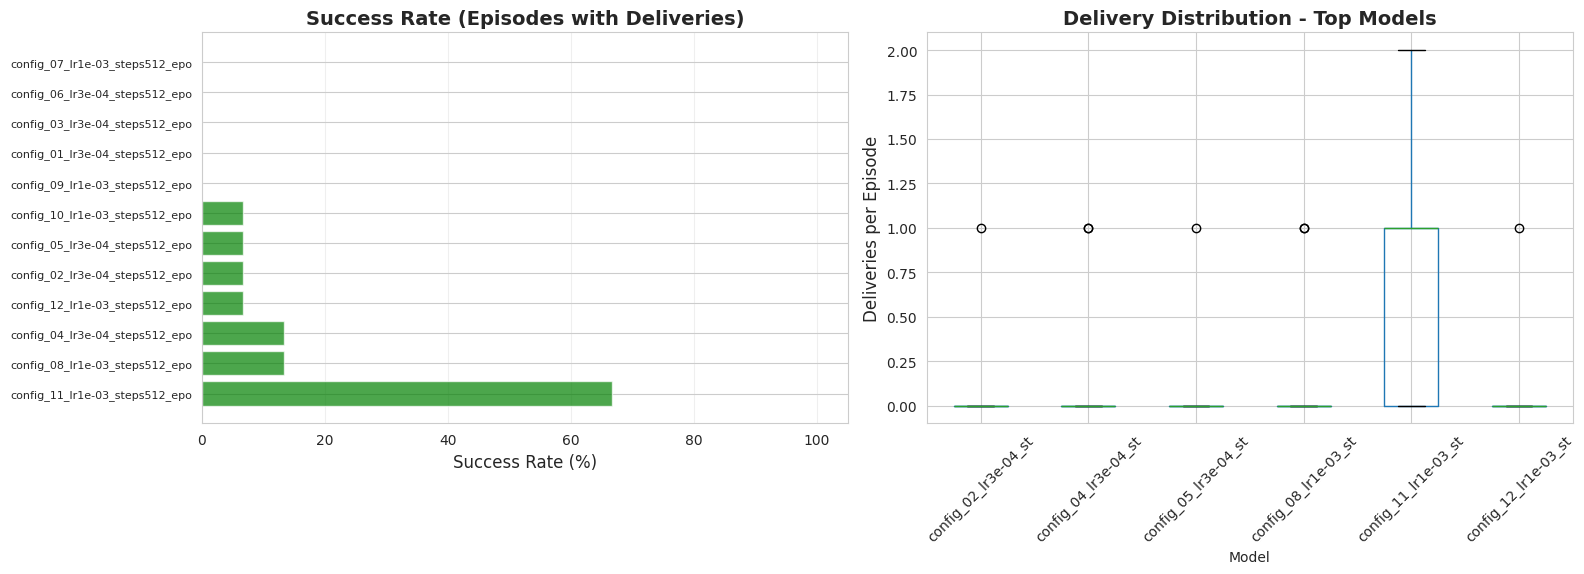

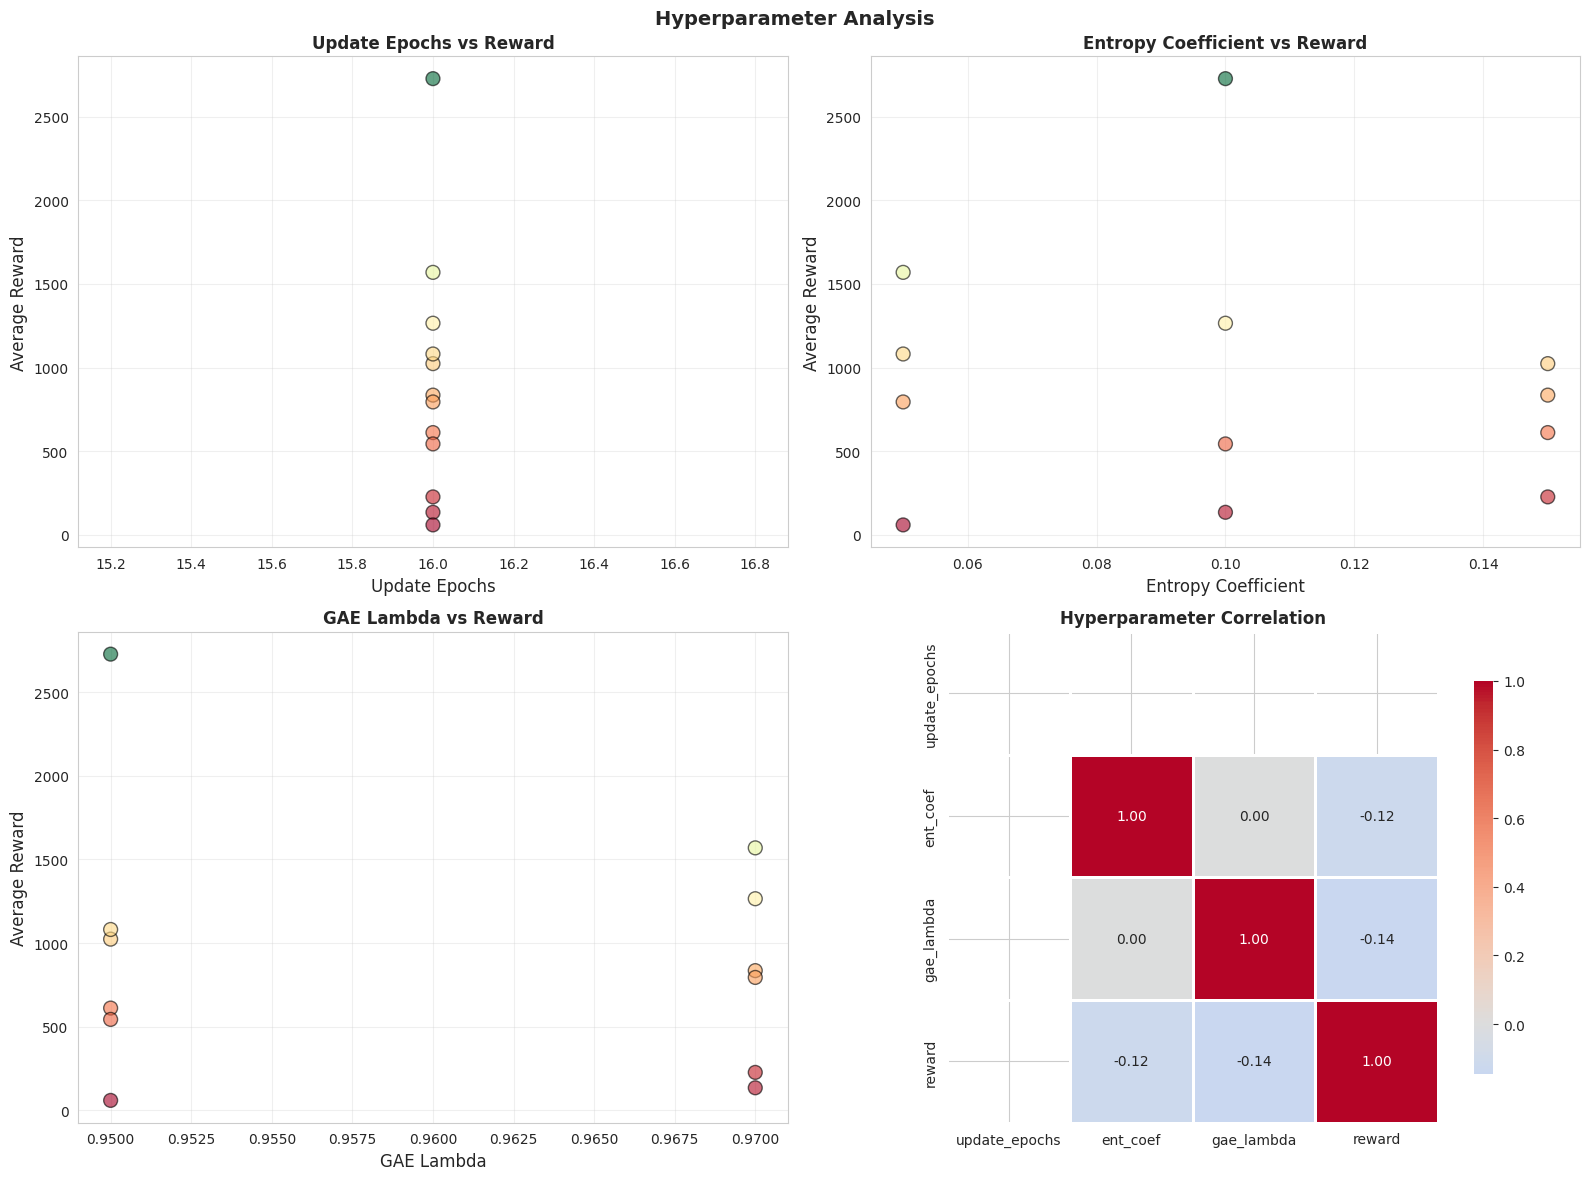

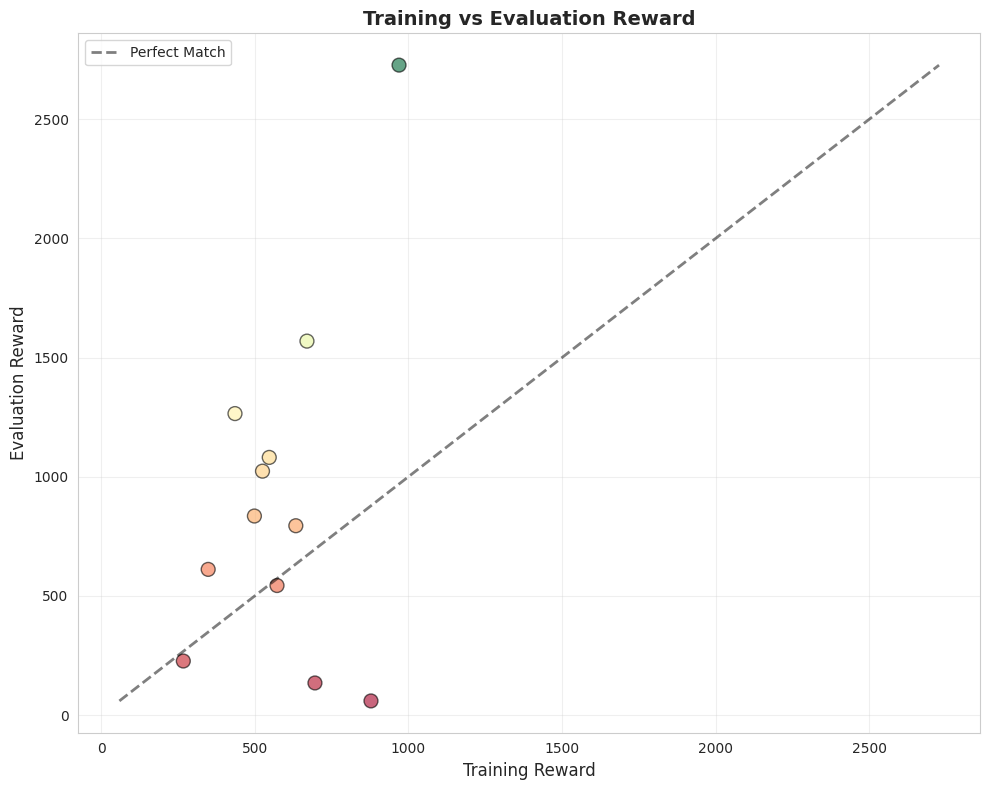

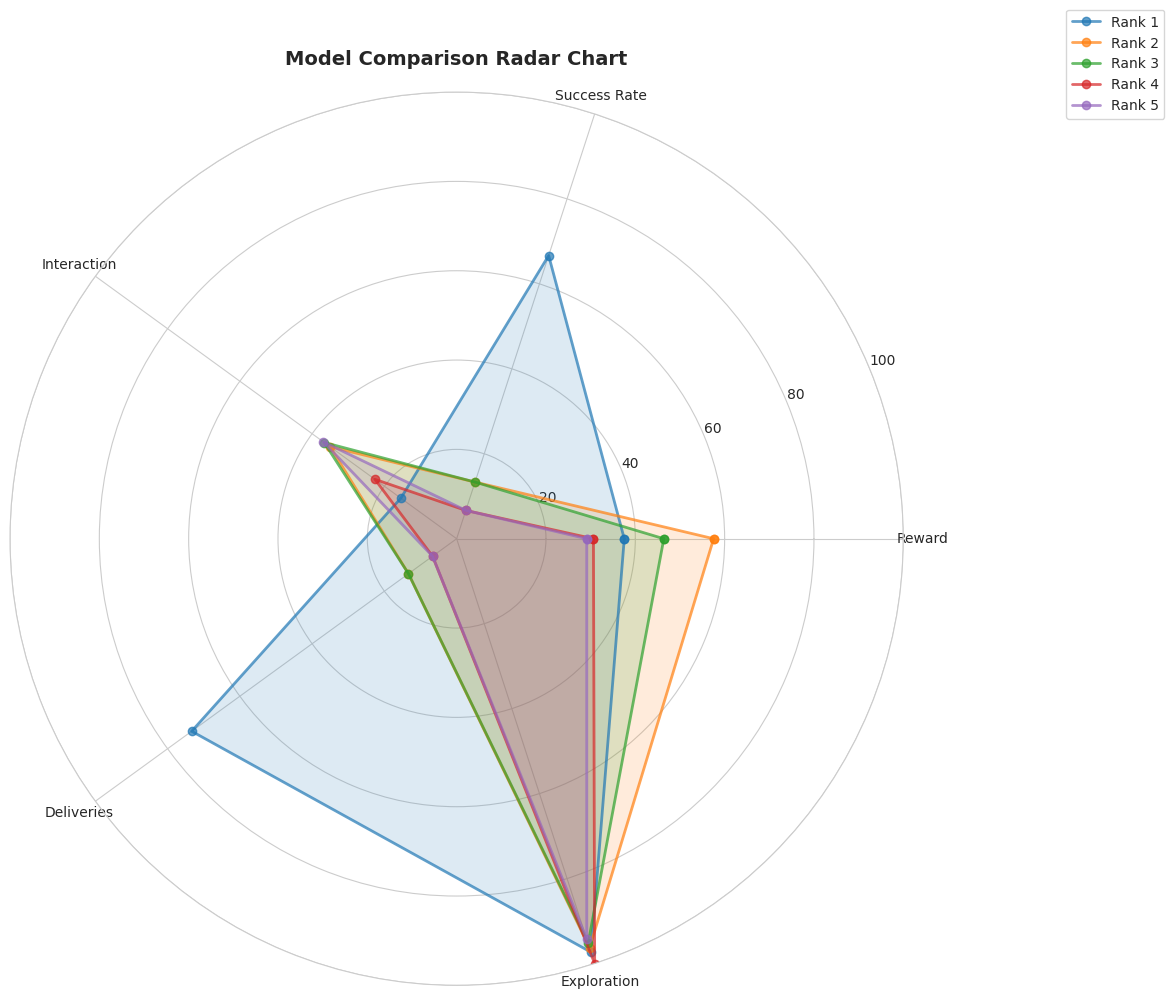

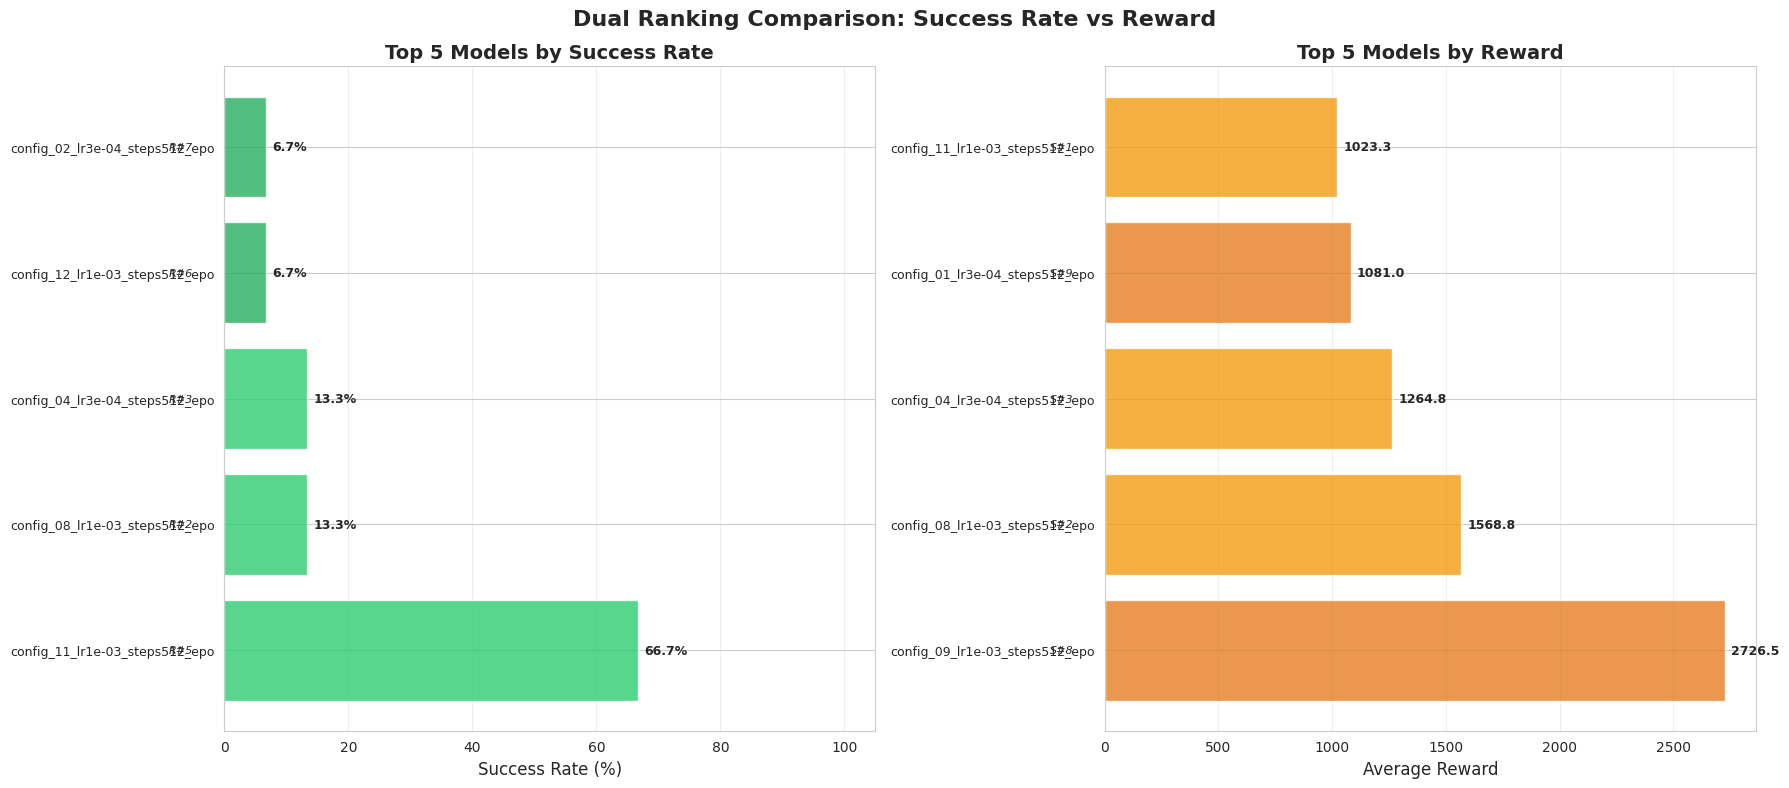

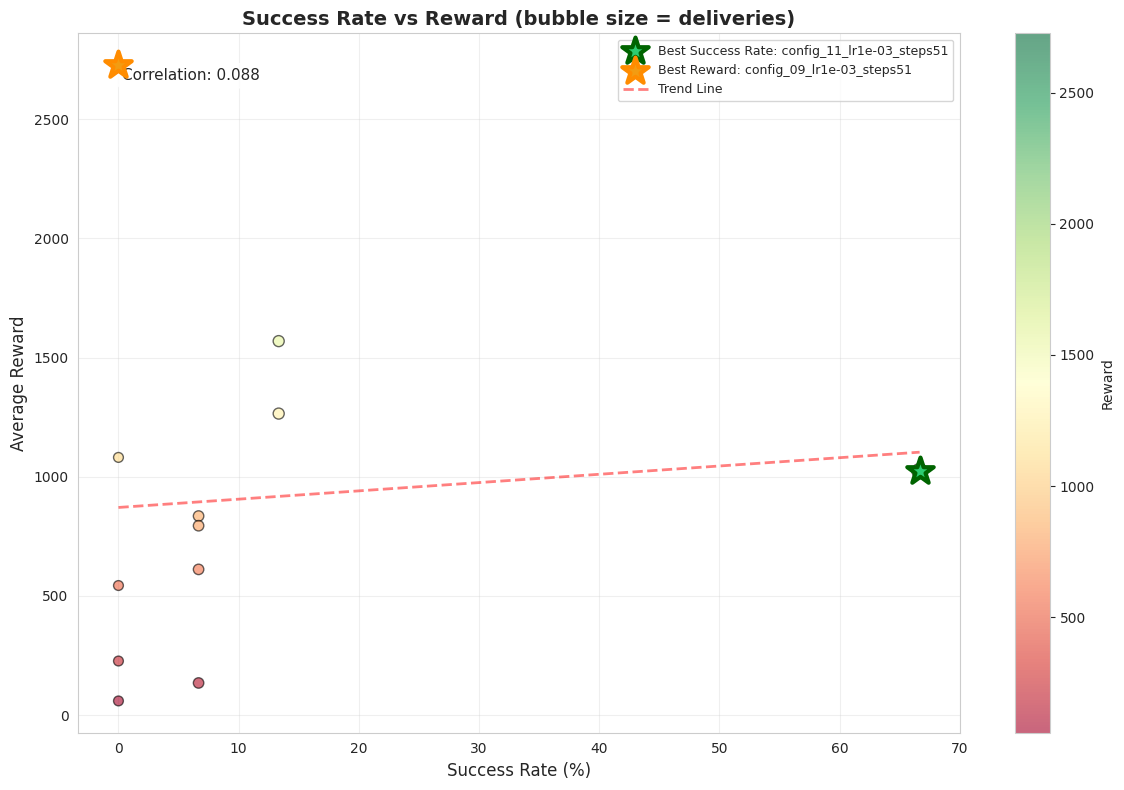

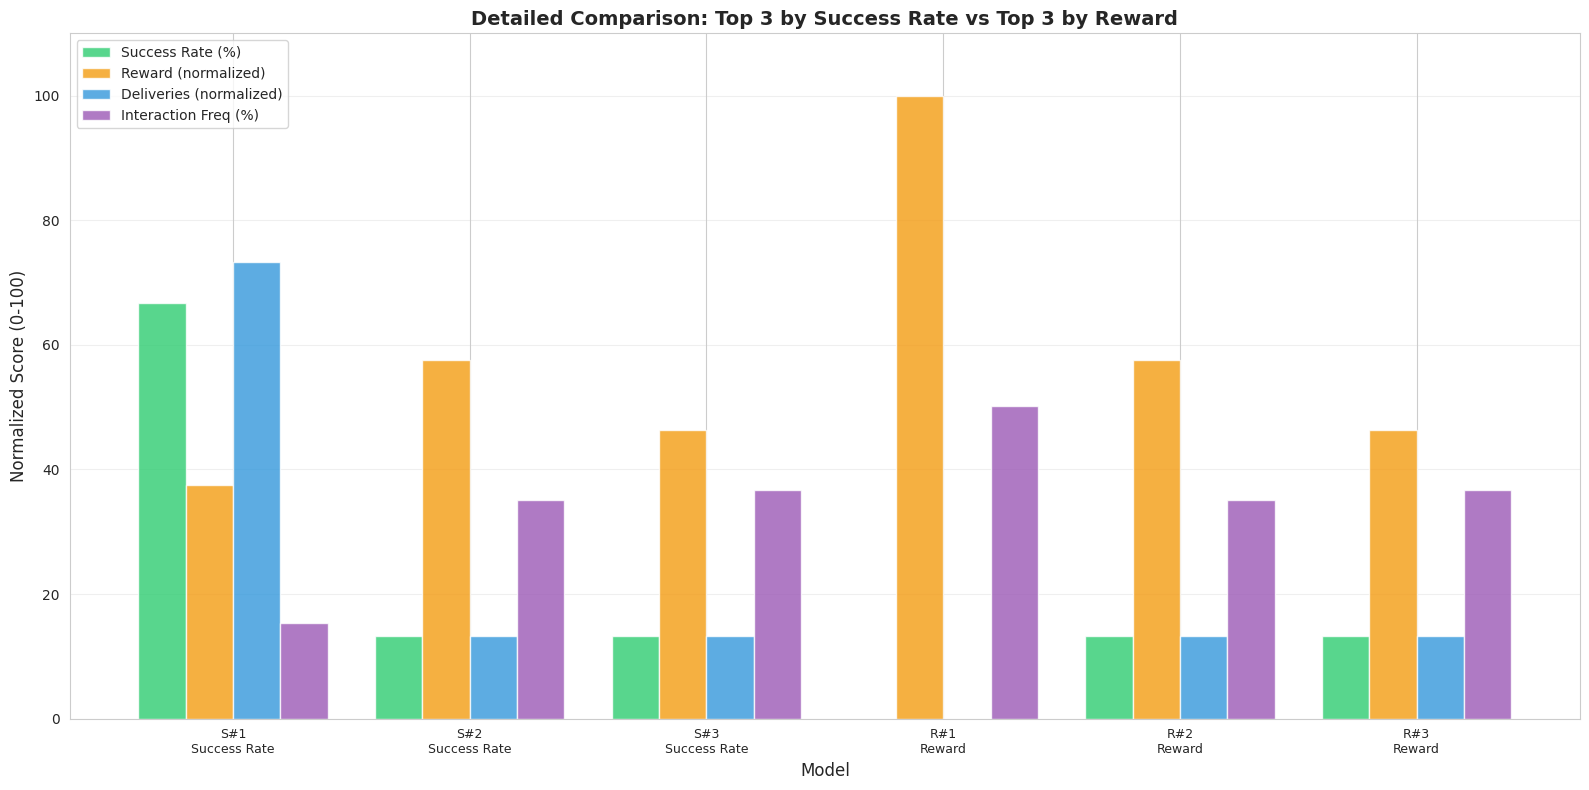

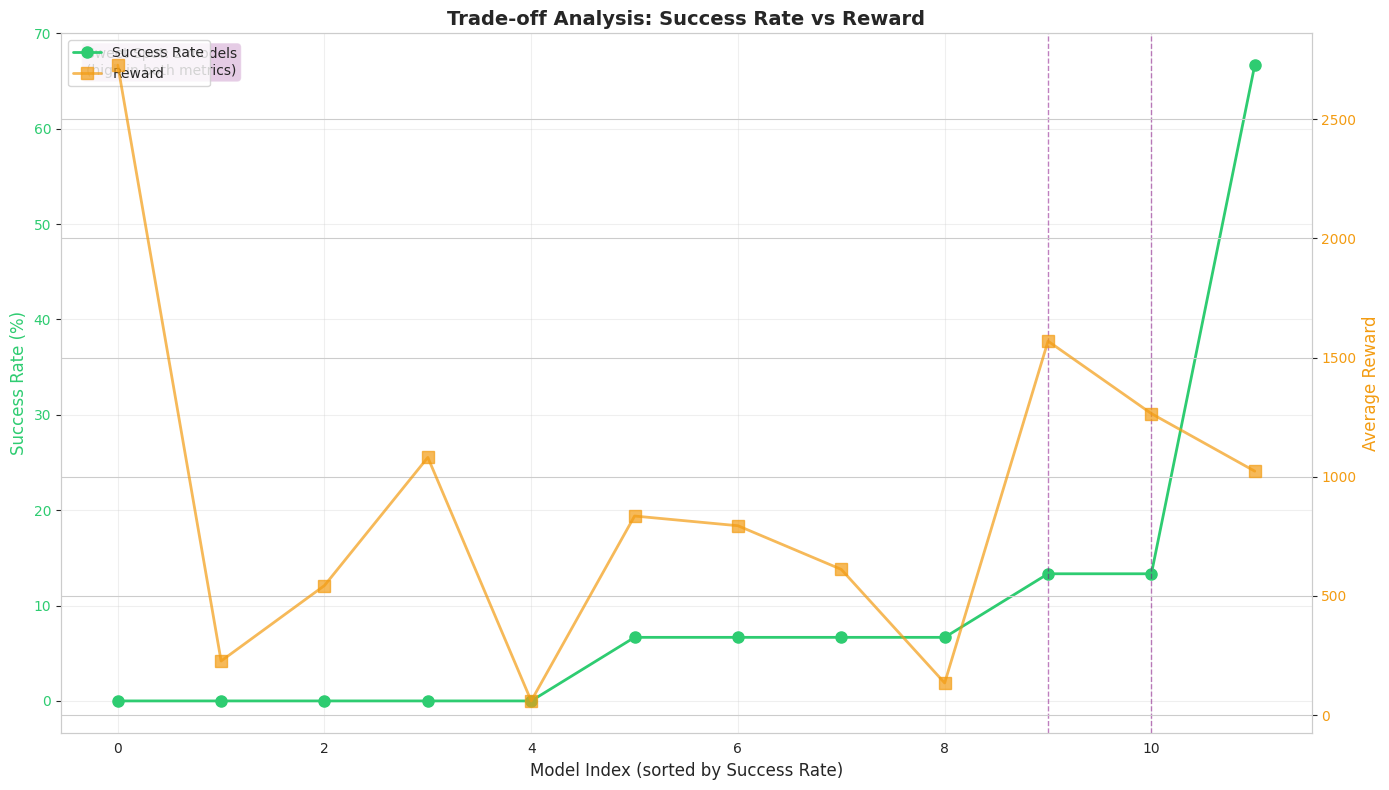

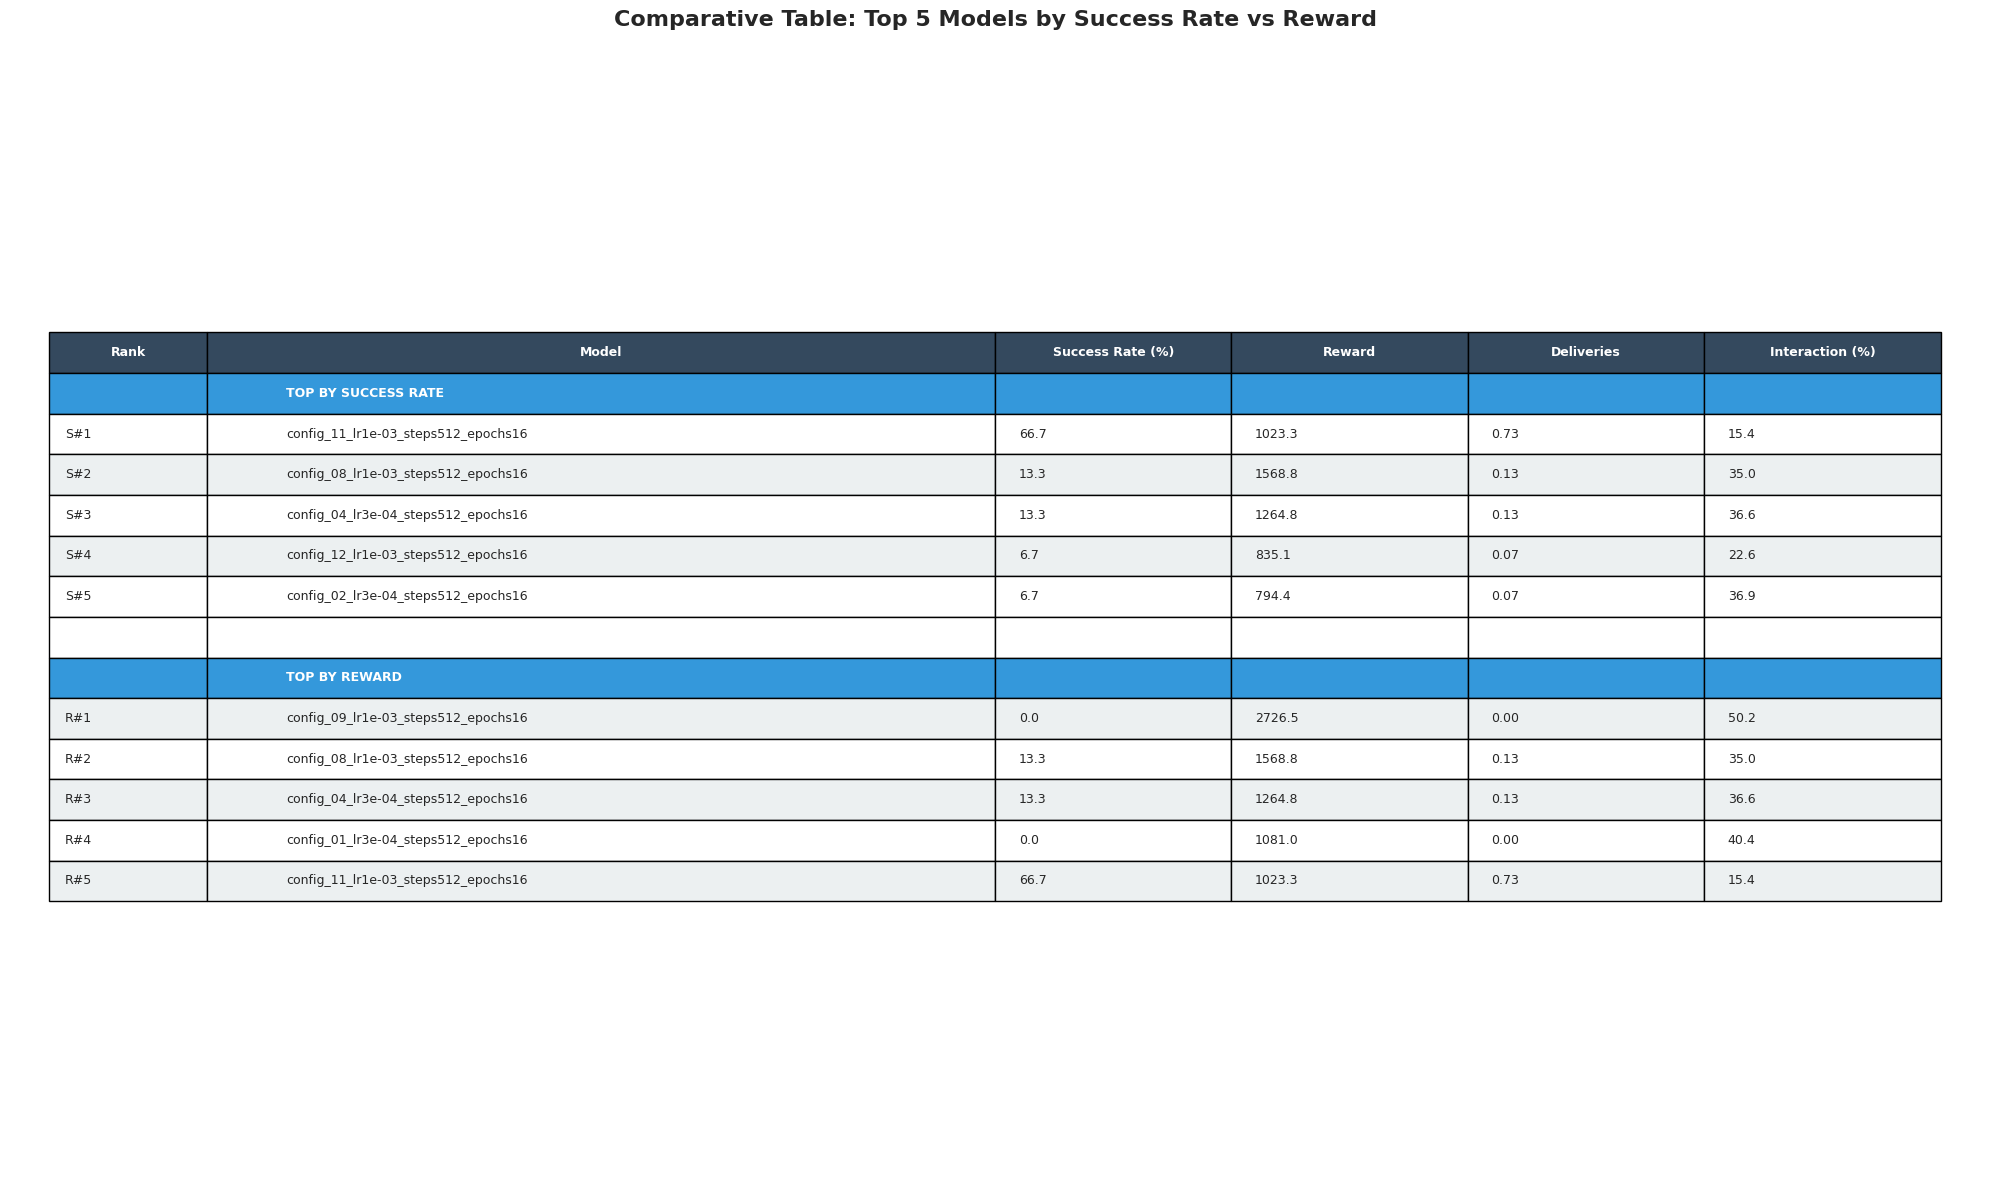


Analysis plots saved to analysis_output/


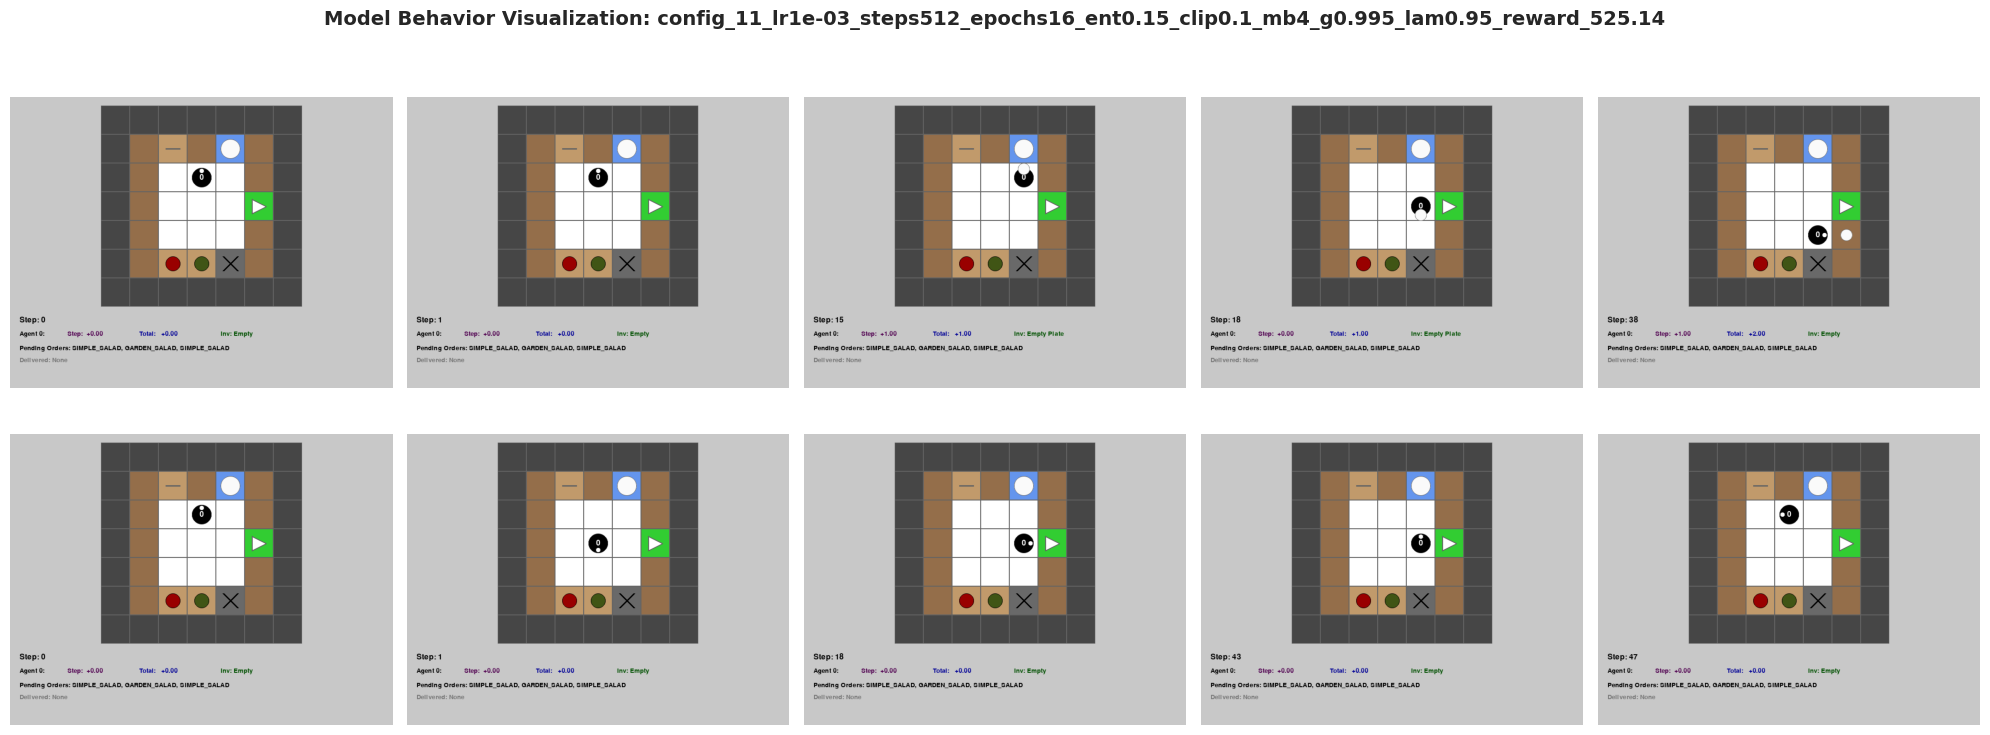

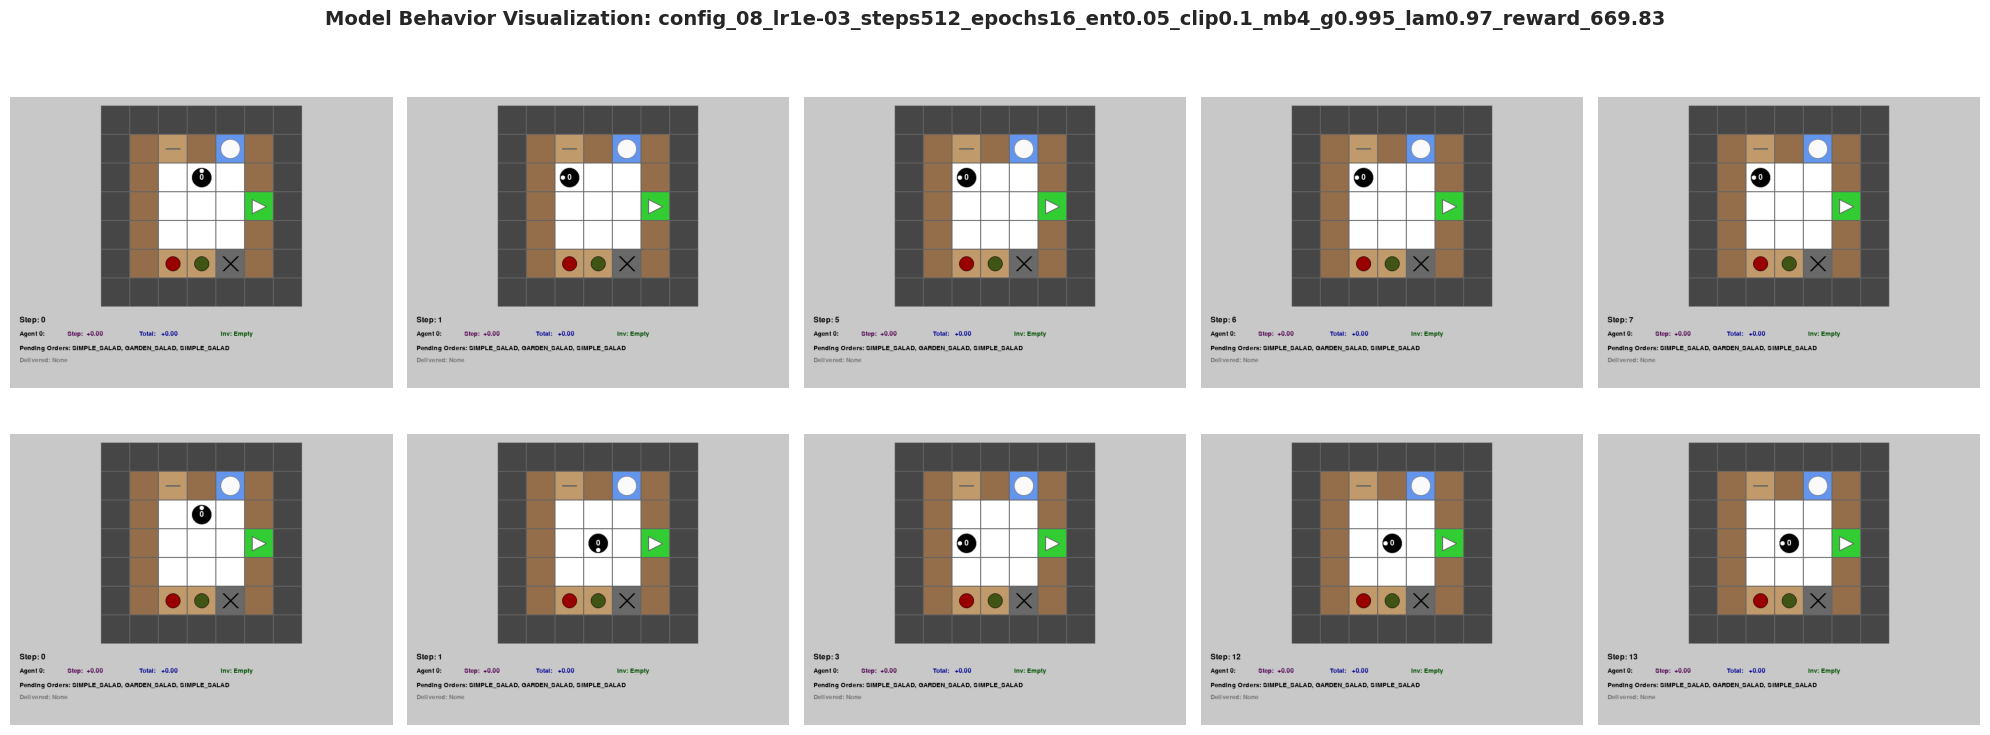

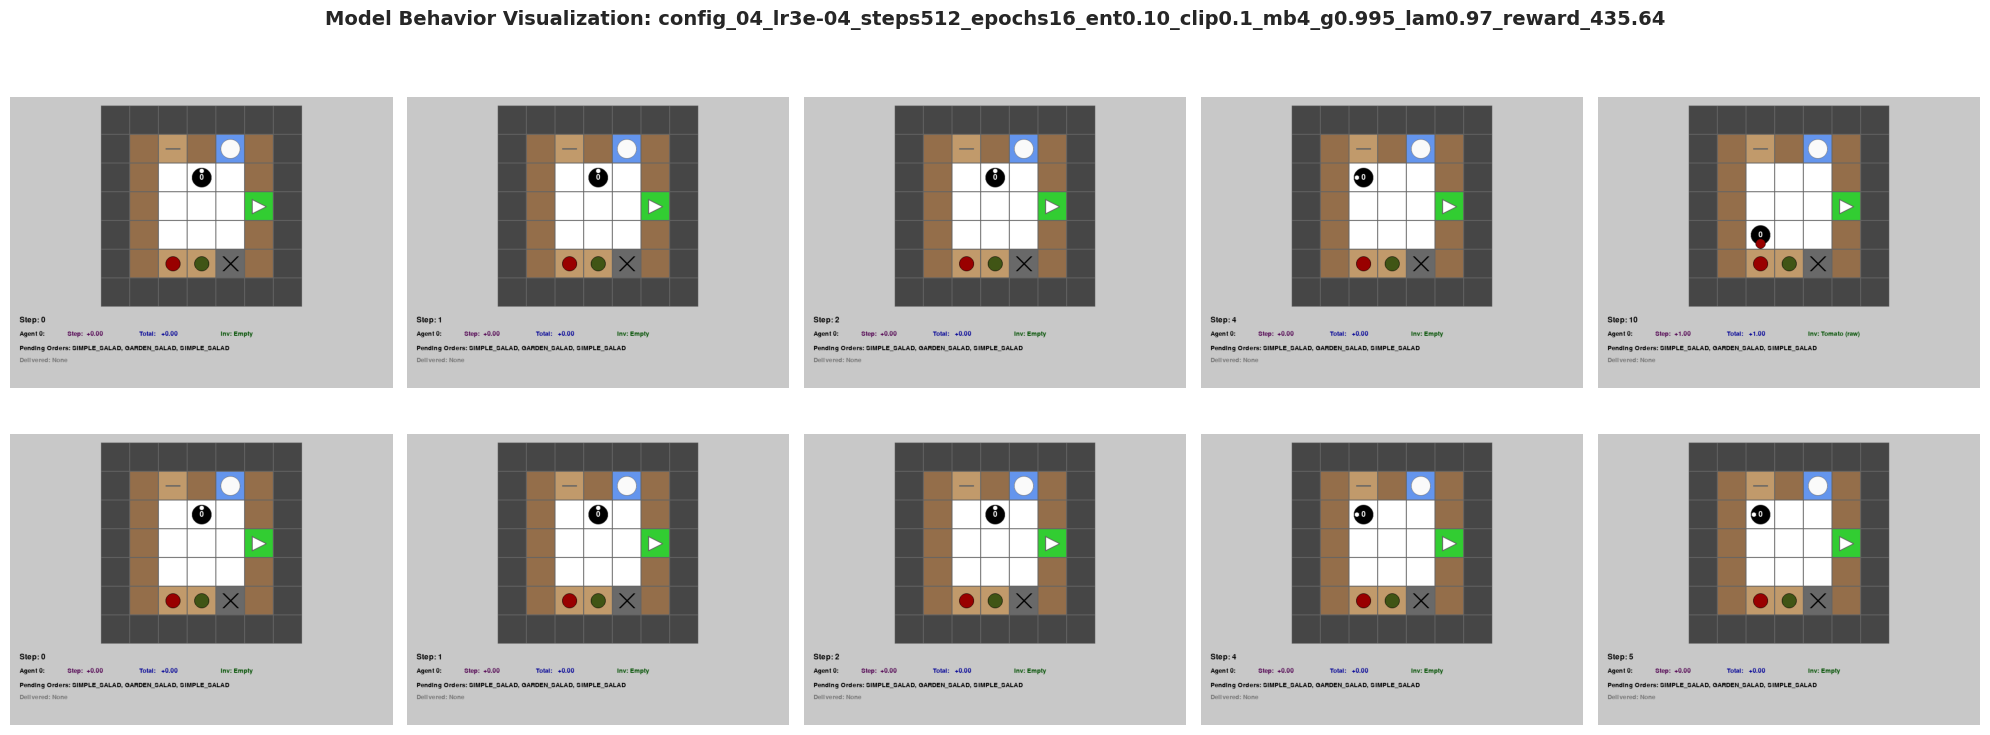


EVALUATION SUMMARY

Top 5 Models:
1. config_11_lr1e-03_steps512_epochs16_ent0.15_clip0.
   Deliveries: 0.73
   Reward: 1023.31 ± 489.41
   Success Rate: 66.7%
   Interaction Freq: 15.4%

2. config_08_lr1e-03_steps512_epochs16_ent0.05_clip0.
   Deliveries: 0.13
   Reward: 1568.79 ± 585.05
   Success Rate: 13.3%
   Interaction Freq: 35.0%

3. config_04_lr3e-04_steps512_epochs16_ent0.10_clip0.
   Deliveries: 0.13
   Reward: 1264.82 ± 427.17
   Success Rate: 13.3%
   Interaction Freq: 36.6%

4. config_12_lr1e-03_steps512_epochs16_ent0.15_clip0.
   Deliveries: 0.07
   Reward: 835.11 ± 419.62
   Success Rate: 6.7%
   Interaction Freq: 22.6%

5. config_02_lr3e-04_steps512_epochs16_ent0.05_clip0.
   Deliveries: 0.07
   Reward: 794.39 ± 394.78
   Success Rate: 6.7%
   Interaction Freq: 36.9%

All plots and visualizations saved to: analysis_output/


In [6]:
# Discover models
model_paths = discover_models()
print(f"Found {len(model_paths)} models")

if not model_paths:
    print("No models found in models/ directory")
else:
    # Evaluate all models
    evaluation_results = []
    
    for model_path in tqdm(model_paths, desc="Evaluating"):
        result = evaluate_model(model_path, num_episodes=15)
        if result:
            evaluation_results.append(result)
    
    if evaluation_results:
        # Save evaluation results to JSON
        results_file = OUTPUT_DIR / "evaluation_results.json"
        serializable_results = [convert_to_serializable(result) for result in evaluation_results]
        json_data = {
            'evaluation_results': serializable_results
        }
        with open(results_file, 'w') as f:
            json.dump(json_data, f, indent=2)
        print(f"Evaluation results saved to: {results_file}")
        
        # Generate analysis plots
        generate_analysis_plots(evaluation_results)
        
        # Visualize top models
        df = pd.DataFrame(evaluation_results)
        df = df.sort_values(['mean_deliveries', 'mean_reward'], ascending=[False, False])
        top_models = df.head(3)
        
        for _, row in top_models.iterrows():
            model_path = Path(row['model_path'])
            visualize_model_behavior(model_path, num_episodes=2, save_frames=True)
        
        # Summary
        print("\n" + "=" * 70)
        print("EVALUATION SUMMARY")
        print("=" * 70)
        df_summary = pd.DataFrame(evaluation_results)
        df_summary = df_summary.sort_values(['mean_deliveries', 'mean_reward'], ascending=[False, False])
        
        print("\nTop 5 Models:")
        for i, (_, row) in enumerate(df_summary.head(5).iterrows(), 1):
            print(f"{i}. {row['filename'][:50]}")
            print(f"   Deliveries: {row['mean_deliveries']:.2f}")
            print(f"   Reward: {row['mean_reward']:.2f} ± {row['std_reward']:.2f}")
            print(f"   Success Rate: {row['success_rate']*100:.1f}%")
            print(f"   Interaction Freq: {row['interaction_frequency']*100:.1f}%")
            print()
        
        print(f"All plots and visualizations saved to: {OUTPUT_DIR}/")


## Model Visualization (Standalone)


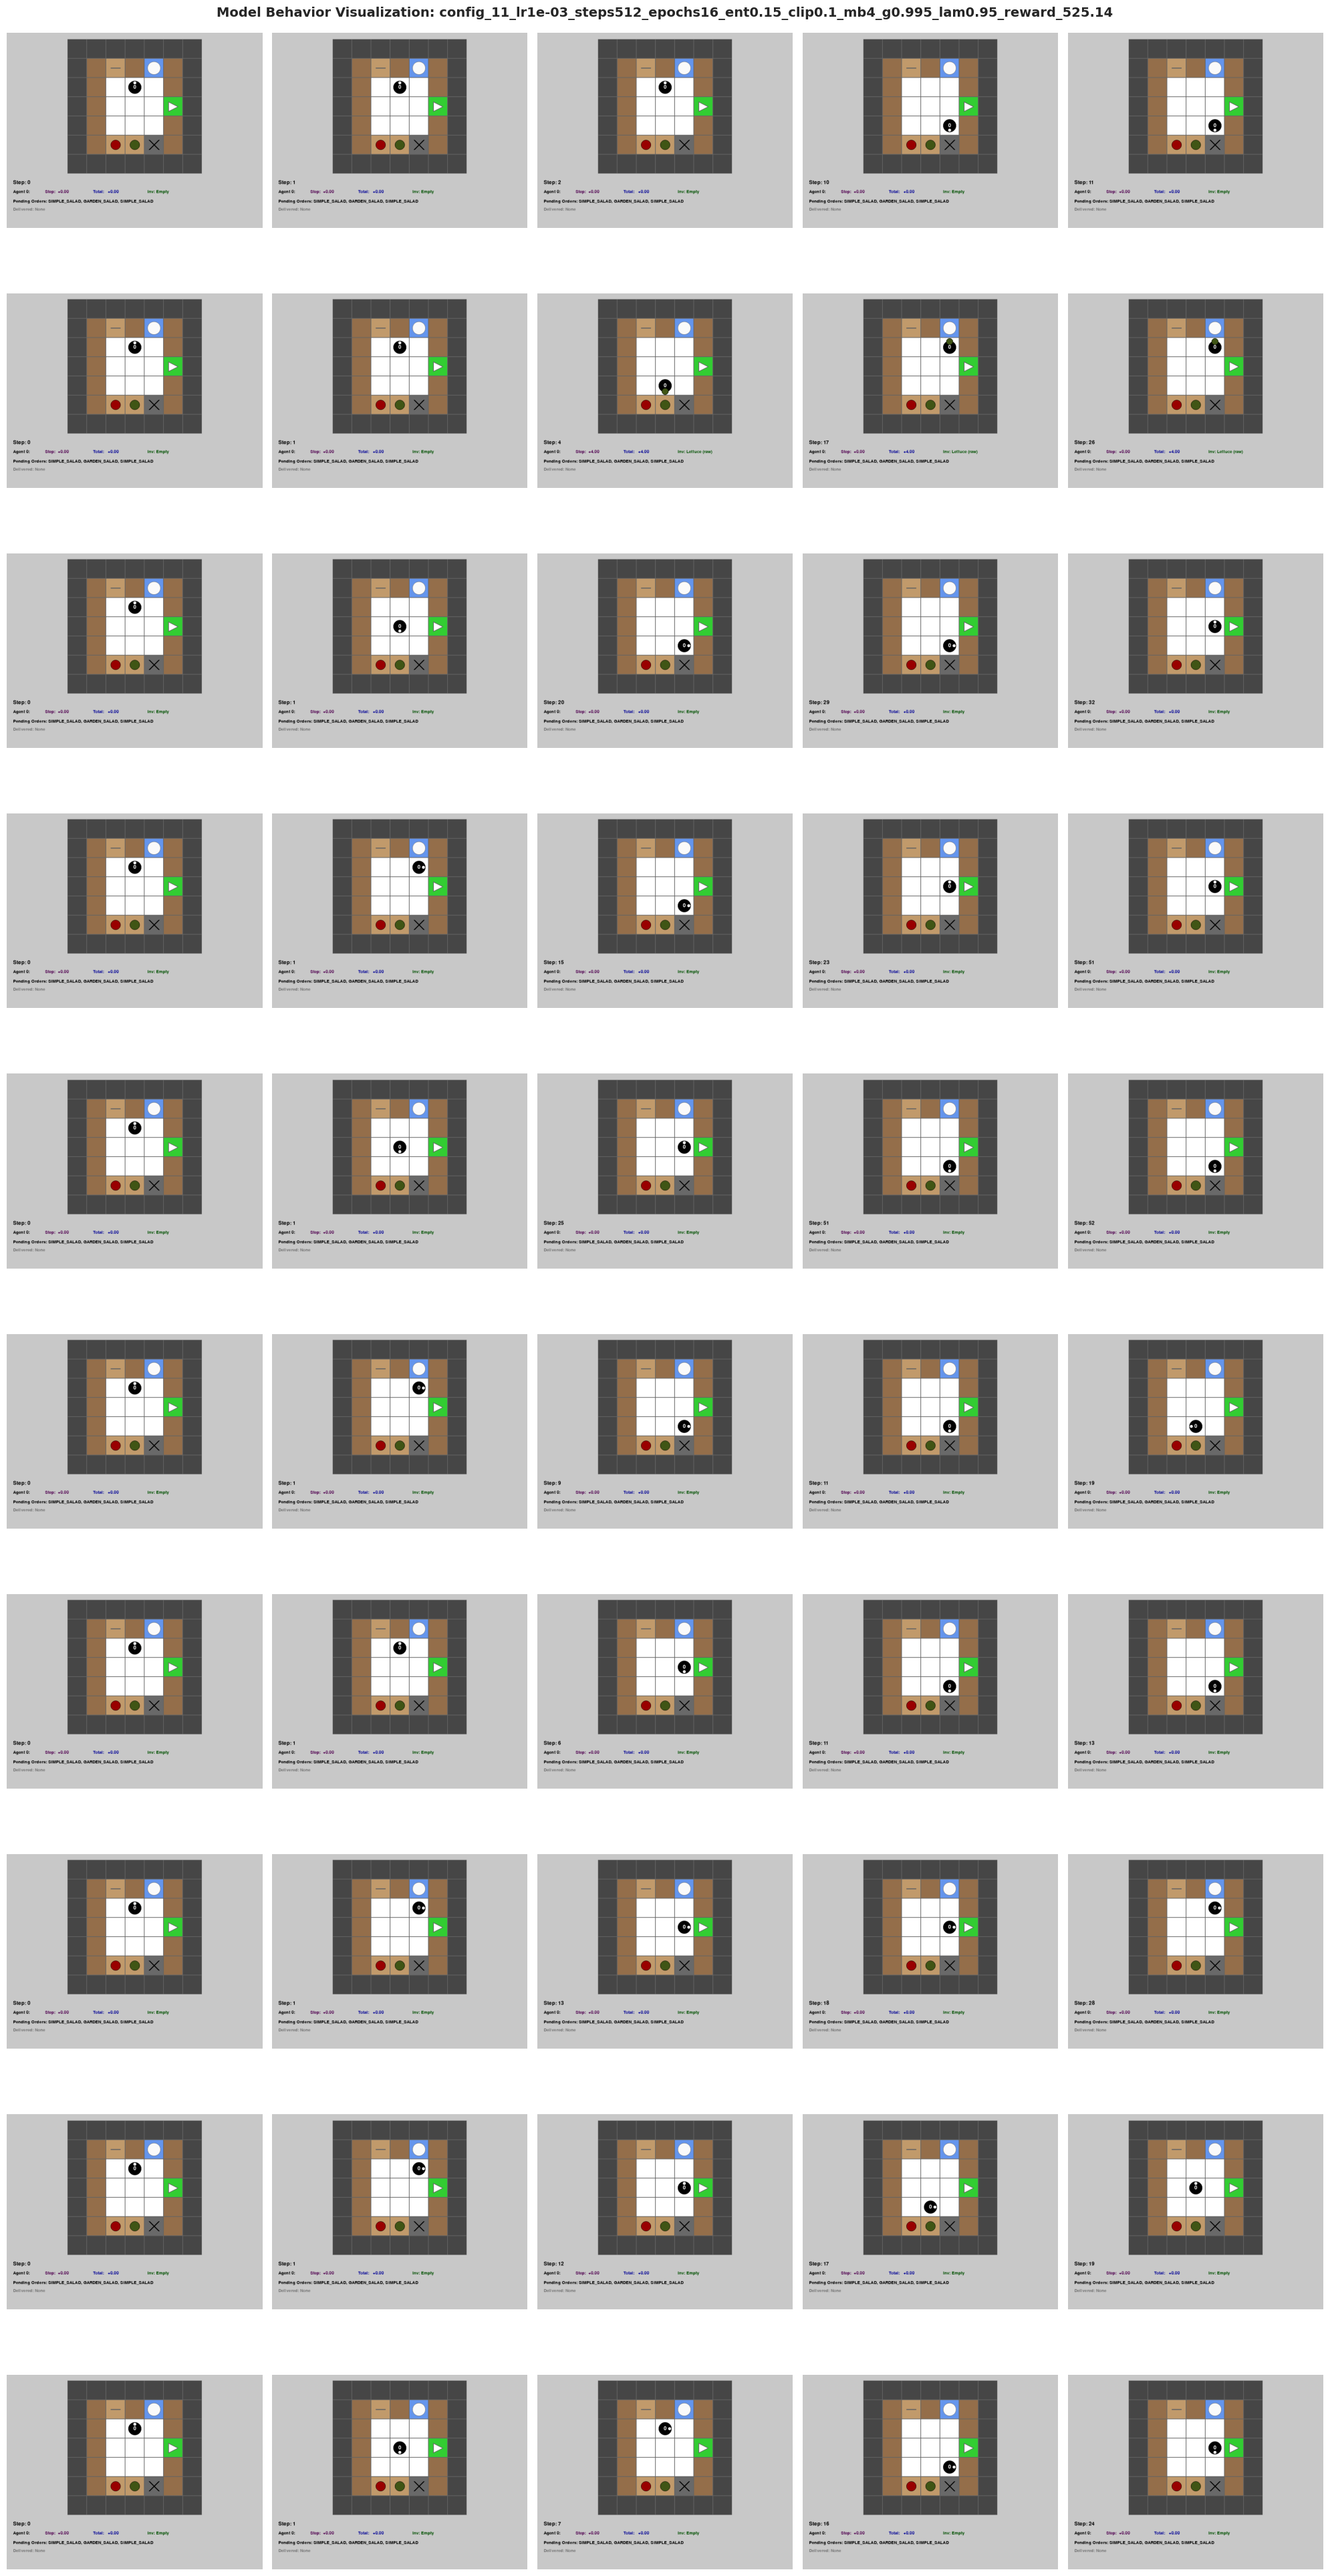

In [15]:
results_file = OUTPUT_DIR / "evaluation_results.json"

if results_file.exists():
    with open(results_file, 'r') as f:
        json_data = json.load(f)
    evaluation_results = json_data.get('evaluation_results', [])
    
    if evaluation_results:
        df = pd.DataFrame(evaluation_results)
        df = df.sort_values(['mean_deliveries', 'mean_reward'], ascending=[False, False])
        top_models = df.head(1)
        
        for _, row in top_models.iterrows():
            model_path = Path(row['model_path'])
            visualize_model_behavior(model_path, num_episodes=10, max_steps=800, save_frames=True)
    else:
        print("No evaluation results found in JSON file")
else:
    model_paths = discover_models()
    if model_paths:
        print("Evaluation results file not found. Evaluating all models first...")
        evaluation_results = []
        
        for model_path in tqdm(model_paths, desc="Evaluating"):
            result = evaluate_model(model_path, num_episodes=15)
            if result:
                evaluation_results.append(result)
        
        if evaluation_results:
            df = pd.DataFrame(evaluation_results)
            df = df.sort_values(['mean_deliveries', 'mean_reward'], ascending=[False, False])
            top_models = df.head(5)
            
            for _, row in top_models.iterrows():
                model_path = Path(row['model_path'])
                visualize_model_behavior(model_path, num_episodes=1, max_steps=800, save_frames=True)
        else:
            print("No models could be evaluated")
    else:
        print("No models found in models/ directory")
